# gdpr rag: bi-encoder vs cross-encoder rerank

two retrieval pipelines over the same 607 gdpr chunks, same llm, same prompt

- pipeline 1 (baseline): bi-encoder top 10 → top 3 → llm → answer 1
- pipeline 2 (rerank): same top 10 → cross-encoder rescores all 10 → top 3 → llm → answer 2

run top to bottom. needs the venv from `requirements.txt` and ollama running with `gemma2:9b-instruct-q4_K_M` pulled.
`data/` = inputs (pdf, hand labels), `results/` = everything this notebook writes

## setup

config, both models, an ollama check, and run info (versions, model revisions, gpu) so every number can be traced back

In [1]:
#quiet the windows / hf noise before anything gets imported
import logging
import os
import warnings

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message="IProgress not found")  # no ipywidgets, plain text progress is fine

import hashlib
import html
import importlib.metadata
import json
import platform
import random
import re
import subprocess
import time
import urllib.request
from datetime import datetime
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import ollama
import pandas as pd
import pymupdf
import torch
import transformers
import yaml
from IPython.display import HTML, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from huggingface_hub import try_to_load_from_cache
from huggingface_hub.utils import logging as hf_logging
from sentence_transformers import CrossEncoder, SentenceTransformer

transformers.logging.set_verbosity_error()
hf_logging.set_verbosity_error()  # hides the "unauthenticated requests" nag, models are public
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)

In [2]:
#config, everything tweakable lives here
ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

BI_ENCODER = "sentence-transformers/msmarco-MiniLM-L6-cos-v5"
CROSS_ENCODER = "cross-encoder/ms-marco-MiniLM-L6-v2"  # spec says ms-marco-MiniLM-L-6-v2, hf redirects to this
LLM = "gemma2:9b-instruct-q4_K_M"

TOP_K = 10  # candidates from the bi-encoder
TOP_N = 3  # chunks that go into the prompt
MAX_CHUNK_TOKENS = 350  # bi-encoder cuts at 384, leave room
LLM_OPTIONS = {"temperature": 0, "seed": 42, "num_ctx": 4096, "num_predict": 400}
SEED = 42
TIMING_WARMUPS = 5  # untimed runs first, the first calls are always slow
TIMING_REPEATS = 10  # every eval question this many times for the retrieval timings
#(name, question, same question with "not", the rule chunk + its exception chunk)
NEGATION_PAIRS = (
    ("breach", "when does a company have to tell people about a data breach?",
     "when does a company not have to tell people about a data breach?", ("art34.1", "art34.3")),
    ("erasure", "when do i have the right to have my data erased?",
     "when do i not have the right to have my data erased?", ("art17.1", "art17.3")),
)
SCALING_BATCH_SIZE = 32  # cross-encoder batch when scoring all 607 pairs
SCALING_SIZES = (607, 10_000, 100_000, 1_000_000, 10_000_000)  # first one measured, the rest extrapolated
#case studies: the fixed ones (every category), then the hurt one and two pool gaps
SHOWCASES = (("eval", "kt02"), ("stress", "s02"), ("stress", "s18"), ("stress", "s21"),
             ("stress", "s15"), ("stress", "s17"), ("eval", "ex01"), ("stress", "s13"))

#chart colours, series always in this order
SURFACE, INK, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#c9c8c3"
SERIES, ORANGE, QUIET = "#2a78d6", "#eb6834", "#a9a8a3"  # blue, orange, grey for "everything else"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA GeForce RTX 4070 Laptop GPU


In [3]:
#both encoders, same minilm-l6 size, both trained on ms marco
bi_encoder = SentenceTransformer(BI_ENCODER, device=DEVICE)
cross_encoder = CrossEncoder(CROSS_ENCODER, device=DEVICE, max_length=512)
tokenizer = bi_encoder.tokenizer  # all chunk token counts use this one

print("bi-encoder:", BI_ENCODER, "| max_seq_length", bi_encoder.max_seq_length, "| dim", bi_encoder.get_embedding_dimension())
print("bi-encoder modules:", [type(module).__name__ for module in bi_encoder])  # ends in Normalize -> dot = cosine
print("cross-encoder:", CROSS_ENCODER, "| max_seq_length", cross_encoder.max_seq_length, "| activation", cross_encoder.activation_fn)  # Identity -> raw logits

bi-encoder: sentence-transformers/msmarco-MiniLM-L6-cos-v5 | max_seq_length 384 | dim 384
bi-encoder modules: ['Transformer', 'Pooling', 'Normalize']
cross-encoder: cross-encoder/ms-marco-MiniLM-L6-v2 | max_seq_length 512 | activation Identity()


In [4]:
#ollama has to be up with the model pulled, first call also loads it into memory
def ollama_placement(name: str) -> str:
    #ollama ps shows how much of the model sits on gpu vs cpu
    listing = subprocess.run(["ollama", "ps"], capture_output=True, text=True).stdout
    row = next((line for line in listing.splitlines() if line.startswith(name)), "")
    found = re.search(r"\d+%/\d+% CPU/GPU|\d+% (?:GPU|CPU)", row)
    return found.group() if found else "not loaded"


reply = ollama.chat(
    model=LLM,
    messages=[{"role": "user", "content": "reply with just: ok"}],
    options={**LLM_OPTIONS, "num_predict": 5},
    keep_alive="30m",
)
print("ollama says:", reply.message.content.strip(), "| placement:", ollama_placement(LLM))

ollama says: ok | placement: 24%/76% CPU/GPU


In [5]:
#run info, so every number here can be traced back to exact versions + hardware
def hf_revision(repo_id: str) -> str:
    return Path(try_to_load_from_cache(repo_id, "config.json")).parent.name  # .../snapshots/<commit>/config.json


def command_output(command: list) -> str:
    try:
        return subprocess.run(command, capture_output=True, text=True).stdout.strip()
    except OSError:
        return "unavailable"  # tool not installed on this machine


PACKAGES = ("torch", "sentence-transformers", "transformers", "faiss-cpu", "pymupdf", "ollama", "numpy", "pandas")
RUN_INFO = {
    "ran_at": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "os": platform.platform(),
    "gpu": command_output(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"]),
    "cuda": torch.version.cuda,
    "device": DEVICE,
    "packages": {name: importlib.metadata.version(name) for name in PACKAGES},
    "bi_encoder": {"id": BI_ENCODER, "revision": hf_revision(BI_ENCODER)},
    "cross_encoder": {"id": CROSS_ENCODER, "revision": hf_revision(CROSS_ENCODER)},
    "llm": {
        "id": LLM,
        "digest": next(model.digest for model in ollama.list().models if model.model == LLM),
        "ollama": re.search(r"\d+\.\d+\.\d+", command_output(["ollama", "--version"])).group(),
        "placement": ollama_placement(LLM),
        "options": LLM_OPTIONS,
    },
}


def save_run_info() -> None:
    (RESULTS / "run_info.json").write_text(json.dumps(RUN_INFO, indent=2), encoding="utf-8")


save_run_info()
print(json.dumps(RUN_INFO, indent=2))

{
  "ran_at": "2026-10-17T23:21:22",
  "python": "3.11.9",
  "os": "Windows-10-10.0.26300-SP0",
  "gpu": "NVIDIA GeForce RTX 4070 Laptop GPU, 8188 MiB, 617.42",
  "cuda": "12.8",
  "device": "cuda",
  "packages": {
    "torch": "2.11.0+cu128",
    "sentence-transformers": "6.1.0",
    "transformers": "5.20.1",
    "faiss-cpu": "1.15.1",
    "pymupdf": "1.28.2",
    "ollama": "0.6.3",
    "numpy": "2.4.6",
    "pandas": "3.0.6"
  },
  "bi_encoder": {
    "id": "sentence-transformers/msmarco-MiniLM-L6-cos-v5",
    "revision": "14ca9be4bbcf1402eac0f43a2e2ccb6e0f994ba3"
  },
  "cross_encoder": {
    "id": "cross-encoder/ms-marco-MiniLM-L6-v2",
    "revision": "233902d25c440f23af6f7d6e94d2946bac0bee0a"
  },
  "llm": {
    "id": "gemma2:9b-instruct-q4_K_M",
    "digest": "c20bec88025f3aefa420efd64dca0ee4abc8e36078d6b74b0f660cdcbd5d1982",
    "ollama": "0.34.2",
    "placement": "24%/76% CPU/GPU",
    "options": {
      "temperature": 0,
      "seed": 42,
      "num_ctx": 4096,
      "num_pre

## the pdf

gdpr, regulation (eu) 2016/679 as published in oj l 119 (4 may 2016), 88 pages.
`data/gdpr.pdf` is committed and checked by hash, the download is only a fallback

In [6]:
#corpus pdf, checked by hash so we always index the exact same file
GDPR_PDF = DATA / "gdpr.pdf"
GDPR_SHA256 = "bd84e63f5b622b739a83389afc3b30d240f792bb88d8eb03a816c9a82b0c2499"
GDPR_URLS = (
    "https://publications.europa.eu/resource/cellar/3e485e15-11bd-11e6-ba9a-01aa75ed71a1.0006.01/DOC_1",
    "https://eur-lex.europa.eu/legal-content/EN/TXT/PDF/?uri=CELEX:32016R0679",  # sometimes serves a bot check instead
)


def download_gdpr() -> bytes:
    for url in GDPR_URLS:
        try:
            body = urllib.request.urlopen(url, timeout=60).read()
        except OSError as error:
            print("failed:", url, error)
            continue
        if body.startswith(b"%PDF-") and hashlib.sha256(body).hexdigest() == GDPR_SHA256:
            return body
        print("not the expected pdf:", url)  # a 200 with an html page is still a fail
    raise RuntimeError("could not get the gdpr pdf from any source")


if not GDPR_PDF.exists():
    GDPR_PDF.write_bytes(download_gdpr())

assert hashlib.sha256(GDPR_PDF.read_bytes()).hexdigest() == GDPR_SHA256, "data/gdpr.pdf is not the expected file"
doc = pymupdf.open(GDPR_PDF)
assert doc.page_count == 88
RUN_INFO["corpus"] = {"file": "data/gdpr.pdf", "sha256": GDPR_SHA256, "pages": doc.page_count, "source": GDPR_URLS[0]}
print("pages:", doc.page_count)

pages: 88


## pdf -> clean rows

thrown away
- running header at the top of every page (date, "Official Journal of the European Union", page no)
- footnotes at the bottom of a page (their marker digit is a tiny 4.8pt) + the 5.4pt footnote refs inside the text

soft hyphens (u+00ad) at line ends stay for now, `join_rows` glues those words back

In [7]:
HEADER_BOTTOM = 60  # header sits at y≈50, body starts at y≈75
FOOTNOTE_MARKER_SIZE = 5.0  # footnote lines carry a 4.8pt marker digit, the "(" ")" around it are full size
SUPERSCRIPT_SIZE = 6.0  # smaller than this = footnote ref, body text is 9.6


def page_rows(page, page_no: int) -> list:
    #pymupdf gives "1." and its text as separate lines on the same y, so glue spans per visual row
    spans_by_row = {}
    footnotes_from = page.rect.height
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            spans = [span for span in line["spans"] if span["text"].strip()]
            if not spans or line["bbox"][1] < HEADER_BOTTOM:
                continue
            if any(span["size"] < FOOTNOTE_MARKER_SIZE for span in spans):
                footnotes_from = min(footnotes_from, line["bbox"][1])  # 4.8pt digits only exist in footnotes, in-text refs are 5.4
            spans_by_row.setdefault(round(line["bbox"][1]), []).extend(span for span in spans if span["size"] >= SUPERSCRIPT_SIZE)

    rows = []
    for y, spans in sorted(spans_by_row.items()):
        if y >= footnotes_from - 1 or not spans:
            continue  # footnote area
        spans.sort(key=lambda span: span["bbox"][0])
        text = re.sub(r"\s+", " ", " ".join(span["text"] for span in spans)).strip()
        text = re.sub(r"\s*\(\s*\)", "", text)  # some refs only shrink the digit, so "(1)" becomes "()"
        text = re.sub(r"\s+([,.;:)])", r"\1", text)  # a removed footnote ref leaves "Committee ," behind
        rows.append({"page": page_no, "y": y, "x": round(spans[0]["bbox"][0], 1), "font": spans[0]["font"], "text": text})
    return rows


rows = [row for page_no, page in enumerate(doc, start=1) for row in page_rows(page, page_no)]
print("rows:", len(rows))
pd.DataFrame(rows[10:22])

rows:

 3666


,page,y,x,font,text
0,1,381,67.4,EUAlbertina-Regu,"Having regard to the proposal from the European Commission,"
1,1,410,67.4,EUAlbertina-Regu,"After transmission of the draft legislative act to the national parliaments,"
2,1,439,67.4,EUAlbertina-Regu,"Having regard to the opinion of the European Economic and Social Committee,"
3,1,468,67.4,EUAlbertina-Regu,"Having regard to the opinion of the Committee of the Regions,"
4,1,497,67.4,EUAlbertina-Regu,"Acting in accordance with the ordinary legislative procedure,"
5,1,526,67.4,EUAlbertina-Regu,Whereas:
6,1,555,67.4,EUAlbertina-Regu,(1) The protection of natural persons in relation to the processing of personal data is a fundamental right.
7,1,565,94.2,EUAlbertina-Regu,Article 8(1) of the Charter of Fundamental Rights of the European Union (the ‘Charter’) and Article 16(1) of the
8,1,576,94.2,EUAlbertina-Regu,Treaty on the Functioning of the European Union (TFEU) provide that everyone has the right to the protection of
9,1,587,94.2,EUAlbertina-Regu,personal data concerning him or her.


## structure

recitals sit between `Whereas:` and `HAVE ADOPTED THIS REGULATION:`, then chapters / sections / articles.
left out on purpose: the title + citations before `Whereas:` ("Having regard to the Treaty..."), and after article 99 the closing line
("This Regulation shall be binding in its entirety...") + signatures. none of it is a recital or an article

a block = one visual paragraph or point (new block after a big vertical gap, or at an item marker like `(a)` right after a clause ends)

In [8]:
ITEM_START = re.compile(r"^\(([a-z]{1,4}|\d{1,2})\)\s")  # (a), (iv), (12)
PARAGRAPH_START = re.compile(r"^(\d{1,2})\.\s")
CLAUSE_END = (".", ";", ":")
CLOSING = ("This Regulation shall be binding in its entirety", "Done at ")  # end of the articles
BLOCK_GAP = 15  # line spacing is ~10.5, a new paragraph / point jumps ~28

#a few bold headings have a stray space glyph inside a word in the pdf text layer ("Data protection off icer")
BODY_WORDS = {word.lower() for row in rows if "Bold" not in row["font"] for word in re.findall(r"[A-Za-z]+", row["text"])}


def fix_heading(text: str) -> str:
    #glue two tokens when the second isn't a real word but both together are, "off icer" -> "officer"
    tokens = text.split(" ")
    fixed = tokens[:1]
    for token in tokens[1:]:
        if fixed[-1].isalpha() and token.isalpha() and token.lower() not in BODY_WORDS and (fixed[-1] + token).lower() in BODY_WORDS:
            fixed[-1] += token
        else:
            fixed.append(token)
    return " ".join(fixed)


def join_rows(texts: list) -> str:
    #glue wrapped lines, a line ending in a soft hyphen or a real hyphen continues the same word
    joined = ""
    for text in texts:
        if joined.endswith("\xad"):
            joined = joined[:-1] + text
        elif not joined or joined.endswith("-"):
            joined += text
        else:
            joined += " " + text
    return joined


def to_blocks(unit_rows: list) -> list:
    blocks = []
    for index, row in enumerate(unit_rows):
        previous = unit_rows[index - 1] if index else None
        if previous is None:
            new_block = True
        elif row["page"] != previous["page"]:
            new_block = blocks[-1]["texts"][-1].endswith(CLAUSE_END)  # page break mid sentence = same block
        else:
            new_block = row["y"] - previous["y"] > BLOCK_GAP
        #"(2) and (3) ..." after "Article 58(1)," is just a wrapped line, a real point comes after a clause ends
        if new_block or (ITEM_START.match(row["text"]) and blocks[-1]["texts"][-1].endswith(CLAUSE_END)):
            blocks.append({"x": row["x"], "page": row["page"], "texts": [], "pages": []})
        blocks[-1]["texts"].append(row["text"])
        blocks[-1]["pages"].append(row["page"])
    for block in blocks:
        block["text"] = join_rows(block["texts"])
    return blocks


def take_titles(rows: list, index: int, wanted: str, unwanted: str = "") -> tuple:
    #titles can wrap onto 2 lines, take every following row in the title font
    titles = []
    while index < len(rows) and wanted in rows[index]["font"] and not (unwanted and unwanted in rows[index]["font"]):
        titles.append(rows[index]["text"])
        index += 1
    return fix_heading(join_rows(titles)), index


def parse_gdpr(rows: list) -> tuple:
    recitals, articles = [], []
    zone, chapter, section = "preamble", None, None
    index = 0
    while index < len(rows):
        text, font = rows[index]["text"], rows[index]["font"]
        if text == "Whereas:":
            zone = "recitals"
        elif text.startswith("HAVE ADOPTED THIS REGULATION"):
            zone = "articles"
        elif text.startswith(CLOSING):
            break  # closing line + signatures, not part of article 99
        elif zone == "recitals":
            number = re.match(r"^\((\d+)\)\s", text)
            if number and rows[index]["x"] < 70:
                recitals.append({"number": int(number.group(1)), "rows": []})
            recitals[-1]["rows"].append(rows[index])
        elif zone == "articles":
            if re.fullmatch(r"CHAPTER [IVXL]+", text):
                title, index = take_titles(rows, index + 1, "BoldItal")
                chapter, section = f"{text.split()[1]} {title}", None
                continue
            if re.fullmatch(r"Section \d+", text):
                title, index = take_titles(rows, index + 1, "Bold", unwanted="Ital")  # section titles are plain bold, chapter titles bold italic
                section = f"{text.split()[1]} {title}"
                continue
            if re.fullmatch(r"Article \d+", text) and "Ital" in font:
                title, index = take_titles(rows, index + 1, "Bold", unwanted="Ital")
                articles.append({"number": int(text.split()[1]), "title": title, "chapter": chapter, "section": section, "rows": []})
                continue
            articles[-1]["rows"].append(rows[index])
        index += 1
    return recitals, articles


recitals, articles = parse_gdpr(rows)
assert [recital["number"] for recital in recitals] == list(range(1, 174)), "recitals missing or out of order"
assert [article["number"] for article in articles] == list(range(1, 100)), "articles missing or out of order"
print("recitals:", len(recitals), "| articles:", len(articles))
print("art 17:", articles[16]["title"], "|", articles[16]["chapter"], "|", articles[16]["section"])

recitals: 173 | articles: 99
art 17: Right to erasure (‘right to be forgotten’) | III Rights of the data subject | 3 Rectification and erasure


## units

a unit = the smallest piece that still makes sense alone
- an article paragraph, e.g. art 17(3)
- an art 4 definition, e.g. art 4(11) consent
- a whole article when it has no numbered paragraphs
- a recital

every unit keeps its `lead` (the text before its list of points) separate from its `parts` (the points / later subparagraphs),
so a unit that is too long can be split at point boundaries with the lead repeated

In [9]:
def source_rows(blocks: list) -> list:
    #(text, page) of every pdf row behind a unit, used later to find the page a split piece really starts on
    return [(text, page) for block in blocks for text, page in zip(block["texts"], block["pages"])]


def lead_and_parts(blocks: list) -> tuple:
    #first block is the lead, top level points + later subparagraphs are parts, deeper points stay inside their parent
    lead, rest = blocks[0]["text"], blocks[1:]
    item_xs = [block["x"] for block in rest if ITEM_START.match(block["text"])]
    top_x = min(item_xs) if item_xs else min((block["x"] for block in rest), default=0)
    parts = []
    for block in rest:
        if block["x"] <= top_x + 2 or not parts:
            parts.append(block["text"])
        else:
            parts[-1] += "\n" + block["text"]
    return lead, parts


def article_units(article: dict) -> list:
    blocks = to_blocks(article["rows"])
    base = {"kind": "article", "article": article["number"], "article_title": article["title"],
            "chapter": article["chapter"], "section": article["section"]}
    if article["number"] == 4:
        #definitions: one unit each, the "For the purposes of this Regulation:" line is their lead
        units, lead = [], blocks[0]["text"]
        for block in blocks[1:]:
            number = ITEM_START.match(block["text"])
            if number and number.group(1).isdigit() and block["x"] < 75:
                units.append({**base, "paragraph": number.group(1), "page": block["page"], "lead": lead, "parts": [block["text"]],
                              "shared_lead": True, "source": source_rows([block])})
            else:
                units[-1]["parts"][-1] += "\n" + block["text"]  # nested (a) / (b) inside a definition
                units[-1]["source"] += source_rows([block])
        return units
    starts = [index for index, block in enumerate(blocks) if PARAGRAPH_START.match(block["text"]) and block["x"] < 70]
    if not starts:
        lead, parts = lead_and_parts(blocks)
        return [{**base, "paragraph": None, "page": blocks[0]["page"], "lead": lead, "parts": parts, "source": source_rows(blocks)}]
    assert starts[0] == 0, f"article {article['number']} has text before paragraph 1"
    units = []
    for start, end in zip(starts, starts[1:] + [len(blocks)]):
        lead, parts = lead_and_parts(blocks[start:end])
        number = PARAGRAPH_START.match(blocks[start]["text"]).group(1)
        units.append({**base, "paragraph": number, "page": blocks[start]["page"], "lead": lead, "parts": parts,
                      "source": source_rows(blocks[start:end])})
    return units


def recital_unit(recital: dict) -> dict:
    blocks = to_blocks(recital["rows"])
    return {"kind": "recital", "article": None, "article_title": None, "chapter": None, "section": None,
            "paragraph": str(recital["number"]), "page": blocks[0]["page"], "lead": blocks[0]["text"],
            "parts": [block["text"] for block in blocks[1:]], "source": source_rows(blocks)}


units = [unit for article in articles for unit in article_units(article)] + [recital_unit(recital) for recital in recitals]
print("units:", len(units))
print("articles without numbered paragraphs:", [unit["article"] for unit in units if unit["kind"] == "article" and unit["paragraph"] is None])

#paragraphs (and art 4 definitions) must run 1..n inside every article, a gap = something got lost
for number in range(1, 100):
    numbers = [int(unit["paragraph"]) for unit in units if unit["article"] == number and unit["paragraph"]]
    assert numbers == list(range(1, len(numbers) + 1)), f"article {number} paragraphs: {numbers}"

units: 587
articles without numbered paragraphs: [10, 16, 19, 29, 31, 44, 48, 50, 59, 63, 67, 86, 87, 95, 96, 98]


## chunks

every chunk = `header` line + its text. header = `Article 17 - Right to erasure (...)` or `Recital 85`, nothing else gets added.
tokens are counted on that final text with the bi-encoder tokenizer, cap 350. rules, in order
1. a unit that fits = one chunk
2. too long -> split between its parts (points / later subparagraphs). a piece that starts with a point repeats the unit's lead,
   any other later piece starts with a marker like `3. (continued)`
3. one part still too long -> split between sentences
4. one sentence still too long -> split between words right at the cap

short units are never merged, the header gives them enough context

In [10]:
SENTENCE_END = re.compile(r"(?<=[.;])\s+(?=[A-Z‘(])")


def n_tokens(text: str) -> int:
    return len(tokenizer(text)["input_ids"])  # with [CLS] / [SEP], nothing truncated


def unit_header(unit: dict) -> str:
    if unit["kind"] == "recital":
        return f"Recital {unit['paragraph']}"
    return f"Article {unit['article']} - {unit['article_title']}"


def with_prefix(prefix: str, text: str) -> str:
    return f"{prefix}\n{text}" if prefix else text


def fits(header: str, prefix: str, text: str) -> bool:
    return n_tokens(f"{header}\n{with_prefix(prefix, text)}") <= MAX_CHUNK_TOKENS


def sentences_of(text: str) -> list:
    sentences = []
    for sentence in SENTENCE_END.split(text):
        if sentences and sentences[-1].endswith(("e.g.", "i.e.")):
            sentences[-1] += " " + sentence  # abbreviation, not a sentence end
        else:
            sentences.append(sentence)
    return sentences


def words_of(header: str, prefix: str, text: str) -> list:
    #last resort, greedy word windows that just fit
    windows, current = [], []
    for word in text.split(" "):
        if current and not fits(header, prefix, " ".join(current + [word])):
            windows.append(" ".join(current))
            current = []
        current.append(word)
    return windows + [" ".join(current)]


def pack(header: str, first: str, later: str, parts: list, separator: str, rule: str) -> list:
    #greedy: keep adding parts while the piece fits, a part that can't fit even alone goes one level finer
    pieces, current, prefix = [], [], first
    for part in parts:
        if fits(header, prefix, separator.join(current + [part])):
            current.append(part)
            continue
        if current:
            pieces.append({"prefix": prefix, "text": separator.join(current), "rule": rule})
            current, prefix = [], later
        if fits(header, prefix, part):
            current.append(part)
        elif len(sentences_of(part)) > 1:
            pieces += pack(header, prefix, later, sentences_of(part), " ", "sentences")
            prefix = later
        else:
            windows = words_of(header, prefix, part)
            pieces += [{"prefix": prefix if index == 0 else later, "text": window, "rule": "words"} for index, window in enumerate(windows)]
            prefix = later
    if current:
        pieces.append({"prefix": prefix, "text": separator.join(current), "rule": rule})
    return pieces


def unit_pieces(unit: dict) -> list:
    header, body = unit_header(unit), "\n".join([unit["lead"], *unit["parts"]])
    if fits(header, "", body):
        return [{"prefix": "", "text": body, "rule": "none"}]
    #a list of points -> later pieces repeat the lead ("Paragraph 1 shall not apply if one of the following applies:")
    #plain long text -> later pieces just say where they continue from
    has_points = any(ITEM_START.match(part) for part in unit["parts"])
    if unit["kind"] == "recital" or unit["article"] == 4:
        marker = f"({unit['paragraph']}) (continued)"
    elif unit["paragraph"]:
        marker = f"{unit['paragraph']}. (continued)"
    else:
        marker = "(continued)"
    later = unit["lead"] if has_points and n_tokens(unit["lead"]) < MAX_CHUNK_TOKENS // 3 else marker
    pieces = pack(header, "", later, [unit["lead"], *unit["parts"]], "\n", "points" if has_points else "subparagraphs")
    for piece in pieces[1:]:
        if piece["prefix"] == unit["lead"] and not ITEM_START.match(piece["text"]):
            piece["prefix"], piece["rule"] = marker, "subparagraphs"  # a trailing subparagraph is not one of the lead's points
    return pieces


def squash(text: str) -> str:
    return re.sub(r"\s+", "", text.replace("\xad", ""))  # joining lines only ever changes whitespace, so compare without it


def piece_page(unit: dict, text: str) -> int:
    #page where a later piece's own text starts, long units often run onto the next page
    joined, pages = "", []
    for row_text, page in unit["source"]:
        joined += squash(row_text)
        pages += [page] * len(squash(row_text))
    position = joined.find(squash(text)[:80])
    assert position >= 0, f"piece start not found in its unit: {text[:60]}"
    return pages[position]


def unit_id(unit: dict) -> tuple:
    if unit["kind"] == "recital":
        return f"rec{unit['paragraph']}", f"Recital {unit['paragraph']}"
    if unit["paragraph"] is None:
        return f"art{unit['article']}", f"Art. {unit['article']}"
    return f"art{unit['article']}.{unit['paragraph']}", f"Art. {unit['article']}({unit['paragraph']})"


chunk_rows = []
for unit_index, unit in enumerate(units):
    pieces = unit_pieces(unit)
    base_id, base_label = unit_id(unit)
    for number, piece in enumerate(pieces, start=1):
        text = f"{unit_header(unit)}\n{with_prefix(piece['prefix'], piece['text'])}"
        #top level points this piece carries, e.g. (a)-(e), nested sub-points don't count
        points = [ITEM_START.match(part).group(1) for part in unit["parts"] if ITEM_START.match(part) and part in piece["text"]]
        split = len(pieces) > 1
        chunk_rows.append({
            "unit": unit_index,
            "chunk_id": f"{base_id}_p{number}" if split else base_id,
            "label": f"{base_label} part {number}/{len(pieces)}" if split else base_label,
            "kind": unit["kind"],
            "article": unit["article"],
            "paragraph": unit["paragraph"],
            "part": number,
            "parts": len(pieces),
            "points": "" if not (split and points) else f"({points[0]})" if len(points) == 1 else f"({points[0]})-({points[-1]})",
            "split_rule": piece["rule"] if split else "none",
            "page": unit["page"] if number == 1 else piece_page(unit, piece["text"]),
            "chapter": unit["chapter"],
            "section": unit["section"],
            "article_title": unit["article_title"],
            "n_tokens": n_tokens(text),
            "text": text,
            "new_text": piece["text"],  # the part of the text this chunk adds, used by the checks below
        })

chunks = pd.DataFrame(chunk_rows)
print("chunks:", len(chunks), "| from units:", len(units))
chunks.groupby("kind").n_tokens.describe().round(1)

chunks: 607 | from units: 587


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
article,425.0,92.8,69.5,20.0,50.0,69.0,102.0,349.0
recital,182.0,151.4,84.1,30.0,81.0,130.0,208.8,335.0


## checks

the chain pdf rows -> articles / recitals -> units -> chunks must not lose or duplicate a single character.
compared with all whitespace removed, since joining lines only ever changes whitespace

In [11]:
#1. rows: inside the regulation (Whereas: .. Done at) every row is body text or a heading, nothing else got dropped
start = next(index for index, row in enumerate(rows) if row["text"] == "Whereas:")
end = next(index for index, row in enumerate(rows) if row["text"].startswith(CLOSING))
used = {id(row) for item in recitals + articles for row in item["rows"]}
HEADING = re.compile(r"Whereas:|HAVE ADOPTED THIS REGULATION:|CHAPTER [IVXL]+|Section \d+|Article \d+")
dropped = [row for row in rows[start:end] if id(row) not in used]
lost = [row["text"] for row in dropped if not (HEADING.fullmatch(row["text"]) or "Bold" in row["font"])]
assert not lost, lost[:5]
print(f"rows: {len(used)} body rows kept, {len(dropped)} heading rows (article / chapter / section titles)")

#2. articles / recitals -> units, same characters in the same order
for article in articles:
    own = [unit for unit in units if unit["article"] == article["number"]]
    #art 4 definitions all repeat the one "For the purposes of this Regulation:" line, count it once
    unit_text = "".join((unit["lead"] if index == 0 or not unit.get("shared_lead") else "") + "".join(unit["parts"]) for index, unit in enumerate(own))
    assert squash("".join(row["text"] for row in article["rows"])) == squash(unit_text), f"article {article['number']}"
for recital in recitals:
    unit_text = "".join(unit["lead"] + "".join(unit["parts"]) for unit in units if unit["kind"] == "recital" and unit["paragraph"] == str(recital["number"]))
    assert squash("".join(row["text"] for row in recital["rows"])) == squash(unit_text), f"recital {recital['number']}"

#3. units -> chunks, the new text of a unit's pieces adds up to exactly the unit
for unit_index, unit in enumerate(units):
    pieces_text = "".join(chunks.loc[chunks.unit == unit_index, "new_text"])
    assert squash(pieces_text) == squash(unit["lead"] + "".join(unit["parts"])), chunks.loc[chunks.unit == unit_index, "chunk_id"].tolist()

#4. chunk level
assert chunks.chunk_id.is_unique and chunks.text.is_unique
assert chunks.n_tokens.max() <= MAX_CHUNK_TOKENS
#page header ("L 119/12"), soft hyphens, footnote text ("(OJ L 281, 23.11.1995, p. 31)"), emptied refs "()" must all be gone
#"Official Journal of the European Union" itself is fine, articles 45, 92, 99 really say it
for leftover in (r"L 119/\d", "\xad", r"\bOJ [LC] \d", r"\(\)"):
    assert not chunks.text.str.contains(leftover).any(), f"leftover in chunks: {leftover!r}"
print("all checks passed")
print("split rules:", chunks.split_rule.value_counts().to_dict())
print("units split into pieces:", chunks[chunks.parts > 1].groupby("unit").chunk_id.first().str.replace("_p1", "").tolist())

rows: 3390 body rows kept, 256 heading rows (article / chapter / section titles)
all checks passed
split rules: {'none': 570, 'points': 18, 'sentences': 10, 'subparagraphs': 9}
units split into pieces: ['art5.1', 'art9.2', 'art28.3', 'art47.2', 'art49.1', 'art57.1', 'art70.1', 'art83.2', 'rec19', 'rec36', 'rec39', 'rec50', 'rec68', 'rec71', 'rec129', 'rec143', 'rec156']


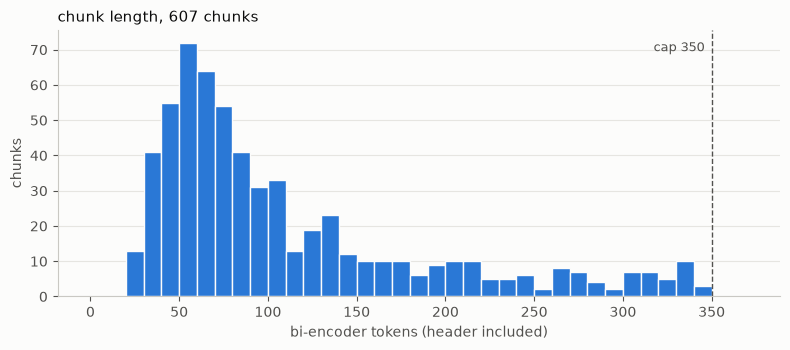

In [12]:
#chunk length, the cap line is where a chunk would start losing text in the bi-encoder (384)
figure, axis = plt.subplots(figsize=(8, 3.6), facecolor=SURFACE)
axis.set_facecolor(SURFACE)
axis.hist(chunks.n_tokens, bins=range(0, MAX_CHUNK_TOKENS + 25, 10), color=SERIES, edgecolor=SURFACE, linewidth=1)
axis.axvline(MAX_CHUNK_TOKENS, color=MUTED, linestyle="--", linewidth=1)
axis.text(MAX_CHUNK_TOKENS - 4, axis.get_ylim()[1] * 0.92, f"cap {MAX_CHUNK_TOKENS}", ha="right", color=MUTED, fontsize=9)
axis.set_title(f"chunk length, {len(chunks)} chunks", loc="left", color=INK, fontsize=11)
axis.set_xlabel("bi-encoder tokens (header included)", color=MUTED)
axis.set_ylabel("chunks", color=MUTED)
axis.tick_params(colors=MUTED)
axis.grid(axis="y", color=GRID, linewidth=0.8)
axis.set_axisbelow(True)
for side in ("top", "right"):
    axis.spines[side].set_visible(False)
for side in ("left", "bottom"):
    axis.spines[side].set_color(AXIS)
figure.tight_layout()
figure.savefig(FIGURES / "chunk_tokens.png", dpi=200, facecolor=SURFACE)
plt.show()

a few chunks worth eyeballing: a definition, a rule + its exception, and a recital that covers the same thing as an article

In [13]:
for chunk_id in ("art4.11", "art9.1", "art9.2_p1", "art17.3", "art34.3", "rec85"):
    if chunk_id in set(chunks.chunk_id):
        row = chunks.set_index("chunk_id").loc[chunk_id]
        print(f"--- {chunk_id} | {row.label} | page {row.page} | {row.n_tokens} tokens\n{row.text}\n")

--- art4.11 | Art. 4(11) | page 34 | 74 tokens
Article 4 - Definitions
For the purposes of this Regulation:
(11) ‘consent’ of the data subject means any freely given, specific, informed and unambiguous indication of the data subject's wishes by which he or she, by a statement or by a clear affirmative action, signifies agreement to the processing of personal data relating to him or her;

--- art9.1 | Art. 9(1) | page 38 | 77 tokens
Article 9 - Processing of special categories of personal data
1. Processing of personal data revealing racial or ethnic origin, political opinions, religious or philosophical beliefs, or trade union membership, and the processing of genetic data, biometric data for the purpose of uniquely identifying a natural person, data concerning health or data concerning a natural person's sex life or sexual orientation shall be prohibited.

--- art9.2_p1 | Art. 9(2) part 1/2 | page 38 | 324 tokens
Article 9 - Processing of special categories of personal data
2. Paragra

In [14]:
#save. chunking got frozen at checkpoint a, the hash makes sure nothing about the chunks quietly changes later
CHUNKS_FROZEN_SHA256 = "9efa82c7d031b672023feb77f10a8b8e4a1fb9de3c7bb4c13e78b9d6d90f04bd"  # sha256 over "chunk_id \t text" lines
chunks_sha256 = hashlib.sha256("\n".join(chunks.chunk_id + "\t" + chunks.text).encode("utf-8")).hexdigest()
assert chunks_sha256 == CHUNKS_FROZEN_SHA256, "chunks changed since checkpoint a"

chunks["article"] = chunks.article.astype("Int64")  # recitals have no article, plain int would turn into 17.0
chunks = chunks.drop(columns=["unit", "new_text"])
chunks.to_csv(RESULTS / "chunks.csv", index=False, encoding="utf-8", lineterminator="\n")
RUN_INFO["chunks"] = {"count": len(chunks), "max_tokens": int(chunks.n_tokens.max()), "cap": MAX_CHUNK_TOKENS,
                      "articles": int((chunks.kind == "article").sum()), "recitals": int((chunks.kind == "recital").sum()),
                      "sha256": chunks_sha256}
save_run_info()
print("saved results/chunks.csv | frozen hash ok")

saved results/chunks.csv | frozen hash ok


## bi-encoder index

every chunk -> one 384-dim vector, done once before any question. the model ends in a Normalize layer so vectors are unit length
and inner product = cosine. flat index = exact search over all 607 chunks, no approximation, so a rank is a real rank

In [15]:
def sync() -> None:
    if DEVICE == "cuda":
        torch.cuda.synchronize()  # gpu work is async, without this a timer stops too early


CHUNK_TEXT = dict(zip(chunks.chunk_id, chunks.text))
CHUNK_LABEL = dict(zip(chunks.chunk_id, chunks.label))

started = time.perf_counter()
chunk_vectors = bi_encoder.encode(chunks.text.tolist(), batch_size=64, convert_to_numpy=True).astype("float32")
sync()
index_seconds = time.perf_counter() - started

index = faiss.IndexFlatIP(chunk_vectors.shape[1])
index.add(chunk_vectors)
assert index.ntotal == len(chunks)
assert np.allclose(np.linalg.norm(chunk_vectors, axis=1), 1, atol=1e-4)  # unit length, so the scores below are cosines
RUN_INFO["index"] = {"type": "faiss.IndexFlatIP", "vectors": int(index.ntotal), "dim": int(index.d), "build_seconds": round(index_seconds, 2)}
print(f"indexed {index.ntotal} chunks x {index.d} dims in {index_seconds:.2f}s on {DEVICE} (one-off cost)")

indexed 607 chunks x 384 dims in 2.23s on cuda (one-off cost)


## pipeline 1: baseline

query -> same bi-encoder -> top 10 chunks by cosine. the first 3 go to the llm -> answer 1

In [16]:
def retrieve(query: str, k: int = TOP_K) -> pd.DataFrame:
    query_vector = bi_encoder.encode([query], convert_to_numpy=True).astype("float32")
    scores, positions = index.search(query_vector, k)
    return pd.DataFrame({"chunk_id": chunks.chunk_id.values[positions[0]], "cosine": scores[0], "bi_rank": np.arange(1, k + 1)})

## pipeline 2: rerank

the same 10 candidates, but now each (query, chunk) pair goes through the cross-encoder together, so query words attend to chunk words.
scores are raw logits (Identity activation), only the order matters. ties keep the bi-encoder order.
the first 3 after sorting go to the llm -> answer 2

In [17]:
#longest chunk in cross-encoder tokens, so a query + chunk pair can be checked against the 512 limit without re-tokenizing every pair
CHUNK_CE_TOKENS = {chunk_id: len(cross_encoder.tokenizer(text)["input_ids"]) for chunk_id, text in CHUNK_TEXT.items()}
print("longest chunk in cross-encoder tokens:", max(CHUNK_CE_TOKENS.values()), "| limit", cross_encoder.max_seq_length)


def rerank(query: str, candidates: pd.DataFrame) -> pd.DataFrame:
    query_tokens = len(cross_encoder.tokenizer(query)["input_ids"]) - 1  # pair shares one [CLS]
    longest = query_tokens + max(CHUNK_CE_TOKENS[chunk_id] for chunk_id in candidates.chunk_id)
    assert longest <= cross_encoder.max_seq_length, f"a {longest} token pair would get cut"
    pairs = [(query, CHUNK_TEXT[chunk_id]) for chunk_id in candidates.chunk_id]
    scores = cross_encoder.predict(pairs, batch_size=len(pairs), convert_to_numpy=True)  # all 10 in one batch
    order = candidates.assign(ce_score=scores).sort_values(["ce_score", "bi_rank"], ascending=[False, True], kind="stable")
    order["ce_rank"] = np.arange(1, len(order) + 1)
    assert set(order.chunk_id) == set(candidates.chunk_id)  # reorders the same 10, never adds or drops one
    return order.sort_values("bi_rank").reset_index(drop=True)  # bi order kept, ce_rank says where each one moved


def top_ids(table: pd.DataFrame, rank_column: str) -> list:
    return table.nsmallest(TOP_N, rank_column).chunk_id.tolist()

longest chunk in cross-encoder tokens: 349 | limit 512


## prompt + llm

one prompt builder for both pipelines, so the only thing that differs between answer 1 and answer 2 is which 3 passages go in (and their order).
passages go in rank order, each tagged with its label so the answer can cite it. one fresh message per call, no chat history

In [18]:
PROMPT = (
    "You answer questions about the EU GDPR using ONLY the passages below.\n"
    "Do not use outside knowledge. If the passages do not contain the answer, reply exactly: \"Not found in the provided context.\"\n"
    "Cite the passage ids you used in square brackets, e.g. [Art. 17(3)].\n"
    "\n"
    "Passages:\n"
    "{passages}\n"
    "\n"
    "Question: {question}\n"
    "Answer:"
)
RUN_INFO["prompt_template"] = PROMPT
LABEL_TO_ID = {label: chunk_id for chunk_id, label in CHUNK_LABEL.items()}


def build_prompt(query: str, chunk_ids: list) -> str:
    passages = "\n\n".join(f"[{CHUNK_LABEL[chunk_id]}]\n{CHUNK_TEXT[chunk_id]}" for chunk_id in chunk_ids)
    return PROMPT.format(passages=passages, question=query)


def cited_ids(answer: str) -> list:
    #"[Art. 17(3)]" or "[Art. 17(1), Recital 65]" -> chunk ids, anything that isn't a real label is ignored
    labels = [label.strip() for group in re.findall(r"\[([^\[\]]+)\]", answer) for label in re.split(r"[;,]\s*(?=Art\.|Recital)", group)]
    return [LABEL_TO_ID[label] for label in labels if label in LABEL_TO_ID]


def generate(prompt: str) -> dict:
    #one fresh user message per call, no chat history
    started = time.perf_counter()
    response = ollama.chat(model=LLM, messages=[{"role": "user", "content": prompt}], options=LLM_OPTIONS, keep_alive="30m")
    wall_ms = (time.perf_counter() - started) * 1000
    answer = response.message.content.strip()
    assert response.prompt_eval_count + LLM_OPTIONS["num_predict"] <= LLM_OPTIONS["num_ctx"], "prompt too long, ollama would cut it"
    return {
        "answer": answer,
        "cited": cited_ids(answer),
        "truncated": response.done_reason == "length",  # stopped at num_predict, judge it as cut off, not as an omission
        "prompt_tokens": response.prompt_eval_count,  # server-reported prompt tokens; caching affects prefill time
        "output_tokens": response.eval_count,
        "prefill_ms": response.prompt_eval_duration / 1e6,
        "decode_ms": response.eval_duration / 1e6,
        "load_ms": response.load_duration / 1e6,
        "wall_ms": wall_ms,
    }

## eval set

`data/eval_queries.yaml`: 16 questions, 4 per category, written + labelled before any scored run, then frozen (hash below).
each question lists the facts a complete answer needs. a fact lists the chunks that state it, any one of them is enough.
separate facts are all needed. a recital counts the same as an article when its text says it

the aggregate numbers further down come only from this set. targeted failure hunting lives in the stress set

In [19]:
EVAL_FILE = DATA / "eval_queries.yaml"
EVAL_FROZEN_SHA256 = "59889800b3fe7261d04dde24e321540e80fcc593d85a9e911f218b0ba00b97aa"
CATEGORIES = ("keyword_trap", "exception", "negation", "buried")


def load_queries(path: Path) -> tuple:
    raw = path.read_bytes().replace(b"\r\n", b"\n")
    queries = yaml.safe_load(raw)
    ids = [query["id"] for query in queries]
    assert len(set(ids)) == len(ids), "duplicate query ids"
    for query in queries:
        assert query["category"] in CATEGORIES, query["id"]
        for fact in query["facts"]:
            unknown = [chunk_id for chunk_id in fact["support"] if chunk_id not in CHUNK_TEXT]
            assert not unknown, f"{query['id']} cites chunks that don't exist: {unknown}"
    return queries, hashlib.sha256(raw).hexdigest()


eval_queries, eval_sha256 = load_queries(EVAL_FILE)
assert eval_sha256 == EVAL_FROZEN_SHA256, "eval set changed since it was frozen"
RUN_INFO["eval_set"] = {"file": "data/eval_queries.yaml", "sha256": eval_sha256, "queries": len(eval_queries),
                        "facts": sum(len(query["facts"]) for query in eval_queries)}
save_run_info()
pd.DataFrame([{"id": query["id"], "category": query["category"], "facts": len(query["facts"]),
               "support": ", ".join(sorted({chunk_id for fact in query["facts"] for chunk_id in fact["support"]})),
               "query": query["query"]} for query in eval_queries])

,id,category,facts,support,query
0,kt01,keyword_trap,3,art8.1,"How old must a child be to agree to an app using their data on their own, and can an EU country lower that age?"
1,kt02,keyword_trap,3,"art33.1, rec85","When a data controller discovers a personal-data breach, how quickly must it tell the regulator, and what if it is l..."
2,kt03,keyword_trap,3,"art82.1, art82.2, art82.3, rec146","When is a data processor liable to compensate me for harm under the GDPR, and can it avoid liability by proving it w..."
3,kt04,keyword_trap,3,"art12.3, rec59","How long does a company have to respond to my request to see my personal data, and can it take longer?"
4,ex01,exception,2,"art17.1, art17.3, rec65","What is my right to get personal data deleted, and can deletion be refused when the data is needed to defend a legal..."
5,ex02,exception,3,"art9.1, art9.2_p1, rec51","Is using my health information always forbidden, even if I explicitly agree to it?"
6,ex03,exception,2,"art46.1, rec108","Can a company use safeguards to send my data to a country without an EU adequacy decision, and what rights must I st..."
7,ex04,exception,3,"art14.1, art14.2, art14.3, art14.5, rec61, rec62","If a company gets my data from someone else, must it tell me, and what if contacting everyone is impossible or would..."
8,ng01,negation,3,art34.3,"After a high-risk personal-data breach, when can a controller avoid telling each affected person, and when must it u..."
9,ng02,negation,2,"art30.5, rec13",Does having fewer than 250 staff automatically mean an organisation does not need records of its data processing?


## scoring

per question, per pipeline
- `hit@3`: any supporting chunk in the top 3
- `facts@3`: share of the facts covered by the top 3
- `sufficient@3`: every fact covered by the top 3, i.e. the llm got enough to answer fully
- `rr@10`: 1 / rank of the first supporting chunk (0 if none in the 10). its mean is mrr@10
- `facts@10`: share of facts covered anywhere in the 10 candidates. the same for both pipelines by construction (rerank only
  reorders those 10), so it's the ceiling, not a rerank gain

outcome, comparing facts@3 baseline -> rerank (covers every case):
`fixed` insufficient -> sufficient · `improved` more facts, still insufficient · `hurt` fewer facts ·
`same, ok` both sufficient · `same, missing` both insufficient with the same facts · `swapped` same count, different facts.
`pool_gap` = some fact has no support anywhere in the 10, rerank can't fix that one

In [20]:
def score(query: dict, ranked_ids: list) -> dict:
    supporting = {chunk_id for fact in query["facts"] for chunk_id in fact["support"]}
    top = set(ranked_ids[:TOP_N])
    covered = tuple(bool(top & set(fact["support"])) for fact in query["facts"])
    in_pool = [bool(set(ranked_ids) & set(fact["support"])) for fact in query["facts"]]
    first = next((rank for rank, chunk_id in enumerate(ranked_ids, start=1) if chunk_id in supporting), None)
    return {"hit@3": float(bool(top & supporting)), "facts@3": float(np.mean(covered)), "sufficient@3": float(all(covered)),
            "rr@10": 1 / first if first else 0.0, "facts@10": float(np.mean(in_pool)), "covered": covered}


def outcome(baseline: dict, reranked: dict) -> str:
    if reranked["facts@3"] > baseline["facts@3"]:
        return "fixed" if reranked["sufficient@3"] else "improved"
    if reranked["facts@3"] < baseline["facts@3"]:
        return "hurt"
    if baseline["sufficient@3"]:
        return "same, ok"
    return "swapped" if baseline["covered"] != reranked["covered"] else "same, missing"


def evaluate(queries: list, set_name: str) -> tuple:
    candidate_rows, metric_rows = [], []
    for query in queries:
        table = rerank(query["query"], retrieve(query["query"]))
        facts_of = {chunk_id: [str(number) for number, fact in enumerate(query["facts"], start=1) if chunk_id in fact["support"]]
                    for chunk_id in table.chunk_id}
        for row in table.itertuples():
            candidate_rows.append({"set": set_name, "query_id": query["id"], "chunk_id": row.chunk_id, "label": CHUNK_LABEL[row.chunk_id],
                                   "bi_rank": row.bi_rank, "cosine": round(float(row.cosine), 4), "ce_rank": row.ce_rank,
                                   "ce_score": round(float(row.ce_score), 4), "supports_facts": ",".join(facts_of[row.chunk_id])})
        baseline = score(query, table.sort_values("bi_rank").chunk_id.tolist())
        reranked = score(query, table.sort_values("ce_rank").chunk_id.tolist())
        moves = [f"{row.chunk_id} #{row.bi_rank} -> #{row.ce_rank}" for row in table.itertuples() if facts_of[row.chunk_id]]
        metric_rows.append({"set": set_name, "query_id": query["id"], "category": query["category"],
                            "outcome": outcome(baseline, reranked), "pool_gap": baseline["facts@10"] < 1,
                            **{f"baseline_{key}": value for key, value in baseline.items() if key != "covered"},
                            **{f"rerank_{key}": value for key, value in reranked.items() if key not in ("covered", "facts@10")},
                            "support_moves": "; ".join(moves) or "none in the 10"})
    return pd.DataFrame(candidate_rows), pd.DataFrame(metric_rows).rename(columns={"baseline_facts@10": "facts@10"})


eval_candidates, eval_metrics = evaluate(eval_queries, "eval")
eval_metrics[["query_id", "category", "outcome", "pool_gap", "baseline_facts@3", "rerank_facts@3", "baseline_rr@10", "rerank_rr@10", "support_moves"]]

,query_id,category,outcome,pool_gap,baseline_facts@3,rerank_facts@3,baseline_rr@10,rerank_rr@10,support_moves
0,kt01,keyword_trap,"same, ok",False,1.000000,1.000000,1.000000,1.00,art8.1 #1 -> #1
1,kt02,keyword_trap,fixed,False,0.000000,1.000000,0.250000,1.00,art33.1 #4 -> #1
2,kt03,keyword_trap,"same, ok",False,1.000000,1.000000,0.500000,1.00,art82.2 #2 -> #3; rec146 #3 -> #2; art82.3 #4 -> #1
3,kt04,keyword_trap,"same, missing",True,0.000000,0.000000,0.000000,0.00,none in the 10
4,ex01,exception,"same, missing",True,0.000000,0.000000,0.000000,0.00,none in the 10
5,ex02,exception,"same, missing",True,0.000000,0.000000,0.000000,0.00,none in the 10
6,ex03,exception,"same, ok",False,1.000000,1.000000,1.000000,1.00,rec108 #1 -> #1; art46.1 #2 -> #2
7,ex04,exception,improved,True,0.000000,0.333333,0.142857,1.00,rec61 #7 -> #1
8,ng01,negation,"same, missing",False,0.000000,0.000000,0.125000,0.25,art34.3 #8 -> #4
9,ng02,negation,"same, ok",False,1.000000,1.000000,0.500000,1.00,art30.5 #2 -> #1


In [21]:
#aggregate, eval set only
METRICS = ("hit@3", "facts@3", "sufficient@3", "rr@10")


def summarise(metrics: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for pipeline in ("baseline", "rerank"):
        rows.append({"pipeline": pipeline, **{("mrr@10" if name == "rr@10" else name): metrics[f"{pipeline}_{name}"].mean() for name in METRICS},
                     "facts@10 (ceiling)": metrics["facts@10"].mean()})
    return pd.DataFrame(rows).set_index("pipeline").round(3)


eval_summary = summarise(eval_metrics)
eval_summary.to_csv(RESULTS / "eval_summary.csv", lineterminator="\n")
display(eval_summary)
print("outcomes:", eval_metrics.outcome.value_counts().to_dict(), "| questions with a pool gap:", int(eval_metrics.pool_gap.sum()))
eval_metrics.groupby("category")[["baseline_facts@3", "rerank_facts@3", "baseline_rr@10", "rerank_rr@10"]].mean().round(3)

,hit@3,facts@3,sufficient@3,mrr@10,facts@10 (ceiling)
pipeline,,,,,
baseline,0.438,0.396,0.375,0.376,0.646
rerank,0.562,0.500,0.438,0.594,0.646


outcomes: {'same, missing': 7, 'same, ok': 6, 'improved': 2, 'fixed': 1} | questions with a pool gap: 6


,baseline_facts@3,rerank_facts@3,baseline_rr@10,rerank_rr@10
category,,,,
buried,0.083,0.167,0.125,0.312
exception,0.250,0.333,0.286,0.500
keyword_trap,0.500,0.750,0.438,0.750
negation,0.750,0.750,0.656,0.812


## stress set

`data/stress_queries.yaml`: targeted failure hunting, written after seeing the eval results. every query got its labels before it
was run, and every attempt stays in the file in order. these are examples for the case studies, never averaged into a score

In [22]:
STRESS_FILE = DATA / "stress_queries.yaml"
stress_queries, stress_sha256 = load_queries(STRESS_FILE)
RUN_INFO["stress_set"] = {"file": "data/stress_queries.yaml", "sha256": stress_sha256, "queries": len(stress_queries)}
save_run_info()

stress_candidates, stress_metrics = evaluate(stress_queries, "stress")
print("outcomes:", stress_metrics.outcome.value_counts().to_dict(), "| pool gaps:", int(stress_metrics.pool_gap.sum()))
stress_metrics[["query_id", "category", "outcome", "pool_gap", "baseline_facts@3", "rerank_facts@3", "support_moves"]]

outcomes: {'same, missing': 10, 'same, ok': 9, 'fixed': 4, 'hurt': 1} | pool gaps: 10


,query_id,category,outcome,pool_gap,baseline_facts@3,rerank_facts@3,support_moves
0,s01,keyword_trap,"same, ok",False,1.0,1.0,rec85 #1 -> #2; art33.1 #2 -> #1
1,s02,keyword_trap,fixed,False,0.5,1.0,art15.3 #1 -> #1; art12.5 #7 -> #2
2,s03,keyword_trap,"same, ok",False,1.0,1.0,art4.5 #1 -> #1
3,s04,keyword_trap,"same, missing",True,0.0,0.0,none in the 10
4,s05,exception,"same, missing",True,0.0,0.0,none in the 10
5,s06,exception,"same, missing",True,0.0,0.0,none in the 10
6,s07,exception,"same, missing",True,0.0,0.0,none in the 10
7,s08,exception,"same, ok",False,1.0,1.0,art17.3 #2 -> #2; rec65 #3 -> #1
8,s09,negation,"same, ok",False,1.0,1.0,rec85 #1 -> #2; art33.1 #3 -> #4
9,s10,negation,"same, missing",False,0.0,0.0,art37.1 #9 -> #10


In [23]:
#everything retrieval related in two files, the set column tells eval from stress
candidates = pd.concat([eval_candidates, stress_candidates], ignore_index=True)
metrics = pd.concat([eval_metrics, stress_metrics], ignore_index=True)
candidates.to_csv(RESULTS / "candidates.csv", index=False, lineterminator="\n")
metrics.to_csv(RESULTS / "metrics.csv", index=False, lineterminator="\n")
print(f"saved results/candidates.csv ({len(candidates)} rows) and results/metrics.csv ({len(metrics)} rows)")

saved results/candidates.csv (400 rows) and results/metrics.csv (40 rows)


## answers

every eval + stress question goes through both pipelines' top 3 -> same prompt -> gemma2.
`results/answers.csv` is the record the hand labels in `data/answer_labels.yaml` were made against, so it only gets regenerated
when the file is missing or `REGENERATE_ANSWERS = True`. regenerating means every label has to be redone, the hash check in the
next section fails until then. which pipeline goes first flips every question. the timing calls further down never write to it

In [24]:
REGENERATE_ANSWERS = False  # True = ask gemma2 again, then every label in data/answer_labels.yaml has to be redone
ANSWERS_FILE = RESULTS / "answers.csv"


def answer_sha(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:12]


all_queries = [("eval", query) for query in eval_queries] + [("stress", query) for query in stress_queries]
#only when asked to, or when the cache is missing
if REGENERATE_ANSWERS or not ANSWERS_FILE.exists():
    answer_rows = []
    for number, (set_name, query) in enumerate(all_queries):
        table = candidates[(candidates.set == set_name) & (candidates.query_id == query["id"])]
        contexts = {"baseline": top_ids(table, "bi_rank"), "rerank": top_ids(table, "ce_rank")}
        order = ("baseline", "rerank") if number % 2 == 0 else ("rerank", "baseline")  # flip who goes first every question
        for pipeline in order:
            prompt = build_prompt(query["query"], contexts[pipeline])
            result = generate(prompt)
            answer_rows.append({"set": set_name, "query_id": query["id"], "pipeline": pipeline, "called_first": pipeline == order[0],
                                "context": ",".join(contexts[pipeline]), "same_context": set(contexts["baseline"]) == set(contexts["rerank"]),
                                **{key: value for key, value in result.items() if key != "cited"}, "cited": ",".join(result["cited"]),
                                "answer_sha": answer_sha(result["answer"]), "prompt": prompt})
        print(f"{number + 1}/{len(all_queries)} {query['id']}", end=" | ")
    pd.DataFrame(answer_rows).to_csv(ANSWERS_FILE, index=False, lineterminator="\n")

answers = pd.read_csv(ANSWERS_FILE, keep_default_na=False)
assert len(answers) == 2 * len(all_queries)
print(f"\n{len(answers)} answers | truncated: {int((answers.truncated.astype(str) == 'True').sum())} | "
      f"refused: {int(answers.answer.str.contains('Not found in the provided context').sum())}")
answers[["set", "query_id", "pipeline", "context", "cited", "output_tokens", "answer"]].head(6)


80 answers | truncated: 0 | refused: 43


,set,query_id,pipeline,context,cited,output_tokens,answer
0,eval,kt01,baseline,"art8.1,art68.5,rec65",art8.1,61,A child must be at least 16 years old to agree to an app using their data on their own. Member States may provide b...
1,eval,kt01,rerank,"art8.1,art68.1,rec65",art8.1,61,A child must be at least 16 years old to agree to an app using their data on their own. Member States may provide b...
2,eval,kt02,rerank,"art33.1,art33.2,rec86","art33.1,art33.1",81,"The controller shall without undue delay and, where feasible, not later than 72 hours after having become aware of i..."
3,eval,kt02,baseline,"art33.5,art34.1,art34.4",,10,Not found in the provided context.
4,eval,kt03,baseline,"art82.4,art82.2,rec146","art82.2,rec146",85,A data processor is liable for damage caused by processing only if it has not complied with obligations of the GDPR ...
5,eval,kt03,rerank,"art82.3,rec146,art82.2","art82.2,art82.3",85,A data processor is liable for damage caused by processing only if it has not complied with obligations of the GDPR ...


## answer labels

`data/answer_labels.yaml`: one hand label per answer (80), judged against that answer's own 3 passages and the question's facts
- per fact: `stated` / `missing` / `wrong`. a partial statement counts as missing, a citation alone doesn't count as stating
- `unsupported`: the answer says something its own passages don't
- `overall`: `correct` every fact stated and nothing wrong · `incomplete` something missing · `wrong` a wrong fact or an unsupported claim ·
  `refused` the exact "Not found in the provided context." reply

these are proposed labels, still up for review. borderline calls have a note. each label stores the hash of the answer it judged

In [25]:
#every label has to point at exactly one cached answer
QUERY_LOOKUP = {(set_name, query["id"]): query for set_name, query in all_queries}
answer_lookup = answers.set_index(["set", "query_id", "pipeline"])
label_entries = yaml.safe_load((DATA / "answer_labels.yaml").read_text(encoding="utf-8"))
label_rows = []
label_keys = [(item["set"], item["query_id"], item["pipeline"]) for item in label_entries]
assert len(label_keys) == len(set(label_keys)) == len(answers)
assert set(label_keys) == set(answer_lookup.index)

for item in label_entries:
    key = (item["set"], item["query_id"], item["pipeline"])
    cached = answer_lookup.loc[key]
    query = QUERY_LOOKUP[key[:2]]
    assert item["answer_sha"] == cached.answer_sha == answer_sha(cached.answer), key  # judged this exact answer text
    assert len(item["facts"]) == len(query["facts"])
    assert set(item["facts"]) <= {"stated", "missing", "wrong"}
    assert item["overall"] in {"correct", "incomplete", "wrong", "refused"}
    assert item["refused"] == (cached.answer == "Not found in the provided context.")
    assert item["truncated"] == (str(cached.truncated) == "True")
    #the cached answer still matches today's context + prompt
    table = candidates[(candidates.set == key[0]) & (candidates.query_id == key[1])]
    expected_context = top_ids(table, "bi_rank" if key[2] == "baseline" else "ce_rank")
    assert cached.context.split(",") == expected_context, f"cached context drift: {key}"
    assert cached.prompt == build_prompt(query["query"], expected_context), f"cached prompt drift: {key}"
    if item["overall"] == "correct":  # correct has to mean every fact stated and nothing flagged
        assert all(status == "stated" for status in item["facts"])
        assert not any(item[flag] for flag in ("unsupported", "refused", "truncated"))
    label_rows.append({field: item[field] for field in ("set", "query_id", "pipeline", "overall", "unsupported", "refused", "truncated", "note")} |
                      {"fact_labels": ",".join(item["facts"]), "facts_stated": item["facts"].count("stated") / len(item["facts"]),
                       "wrong_facts": item["facts"].count("wrong")})

assessed = answers.merge(pd.DataFrame(label_rows), on=["set", "query_id", "pipeline"], validate="one_to_one",
                         suffixes=("", "_label"))
assessed.to_csv(RESULTS / "answer_assessment.csv", index=False, lineterminator="\n")
#eval set only, the stress answers are examples
eval_answer_summary = assessed[assessed.set == "eval"].groupby("pipeline").agg(
    facts_stated=("facts_stated", "mean"), correct=("overall", lambda values: (values == "correct").mean()),
    wrong=("overall", lambda values: (values == "wrong").mean()), refused=("refused", "mean"), unsupported=("unsupported", "mean"))
eval_answer_summary.to_csv(RESULTS / "answer_summary.csv", lineterminator="\n")
display(eval_answer_summary.round(3))
print("labels:", len(assessed), "| answer hashes and cached prompts match")

,facts_stated,correct,wrong,refused,unsupported
pipeline,,,,,
baseline,0.271,0.188,0.062,0.562,0.062
rerank,0.354,0.188,0.125,0.375,0.125


labels: 80 | answer hashes and cached prompts match


## case studies

the showcase picks from `SHOWCASES`: at least one `fixed` per category, then the `hurt` case and two pool gaps. for each one
- the 10 candidates with both ranks. `move` = bi rank - ce rank (positive = the cross-encoder pulled it up), `supports_facts` = which facts that chunk states
- a rank shift chart (blue = chunks that state a fact, grey band = the top 3 that go to the llm)
- answer 1 vs answer 2 with their labels
- three separate observations: `retrieval_improved` (facts@3 went up), `*_context_sufficient` (that top 3 covers every fact),
  `answer_improved` / `answer_worsened` (more facts stated without more wrong / unsupported claims, or the other way round).
  a rank gain doesn't automatically mean a better answer, that's why they're kept apart


eval/kt02 | keyword_trap | fixed
When a data controller discovers a personal-data breach, how quickly must it tell the regulator, and what if it is late?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
10,art33.5,"5. The controller shall document any personal data breaches, comprising the facts relating to the",0.5631,1,1.5626,5,-4,
11,art34.1,1. When the personal data breach is likely to result in a high risk to,0.5581,2,1.9765,4,-2,
12,art34.4,4. If the controller has not already communicated the personal data breach to the data,0.5545,3,1.1388,6,-3,
13,art33.1,"1. In the case of a personal data breach, the controller shall without undue delay",0.5493,4,5.0320,1,3,"1,2,3"
14,art33.2,2. The processor shall notify the controller without undue delay after becoming aware of a,0.5387,5,3.2721,2,3,
15,art13.3,3. Where the controller intends to further process the personal data for a purpose other,0.4744,6,-4.1359,9,-3,
16,art35.11,"11. Where necessary, the controller shall carry out a review to assess if processing is",0.4643,7,-5.0159,10,-3,
17,rec86,"(86) The controller should communicate to the data subject a personal data breach, without undue",0.4586,8,2.5486,3,5,
18,art14.4,4. Where the controller intends to further process the personal data for a purpose other,0.4499,9,-3.6779,8,1,
19,rec87,(87) It should be ascertained whether all appropriate technological protection and organisational measures have been,0.4483,10,0.0234,7,3,


support moves: art33.1 #4 -> #1


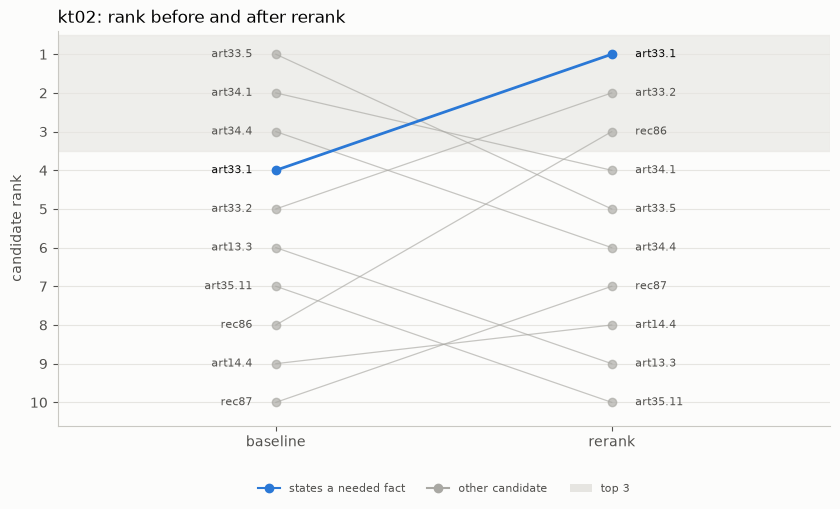

"answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missing,missing,missingno registered support for a complete answer in the supplied passages","answer 2 / rerankThe controller shall without undue delay and, where feasible, not later than 72 hours after having become aware of it, notify the personal data breach to the supervisory authority [Art. 33(1)]. Where the notification to the supervisory authority is not made within 72 hours, it shall be accompanied by reasons for the delay. [Art. 33(1)]parsed citations: art33.1,art33.1label: incompletefacts: stated,missing,stateddeadline and delay reasons stated; unlikely-risk exception omitted"


{'retrieval_improved': True, 'baseline_context_sufficient': False, 'rerank_context_sufficient': True, 'answer_improved': True, 'answer_worsened': False}

stress/s02 | keyword_trap | fixed
do i have to pay a fee to get a copy of my own data?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
170,art15.3,3. The controller shall provide a copy of the personal data undergoing processing. For any,0.4875,1,0.6705,1,0,2
171,rec29,"(29) In order to create incentives to apply pseudonymisation when processing personal data, measures of",0.3493,2,-10.7065,10,-8,
172,rec63,(63) A data subject should have the right of access to personal data which have,0.3391,3,-8.7528,6,-3,
173,rec35,(35) Personal data concerning health should include all data pertaining to the health status of,0.3258,4,-10.3499,9,-5,
174,rec61,(61) The information in relation to the processing of personal data relating to the data,0.3180,5,-8.5614,5,0,
175,art16,The data subject shall have the right to obtain from the controller without undue delay,0.3159,6,-8.5390,4,2,
176,art12.5,5. Information provided under Articles 13 and 14 and any communication and any actions taken,0.3108,7,-7.4558,2,5,1
177,rec33,(33) It is often not possible to fully identify the purpose of personal data processing,0.3058,8,-10.0550,8,0,
178,art21.2,"2. Where personal data are processed for direct marketing purposes, the data subject shall have",0.2985,9,-9.5227,7,2,
179,rec68_p1,"(68) To further strengthen the control over his or her own data, where the processing",0.2933,10,-7.8095,3,7,


support moves: art15.3 #1 -> #1; art12.5 #7 -> #2


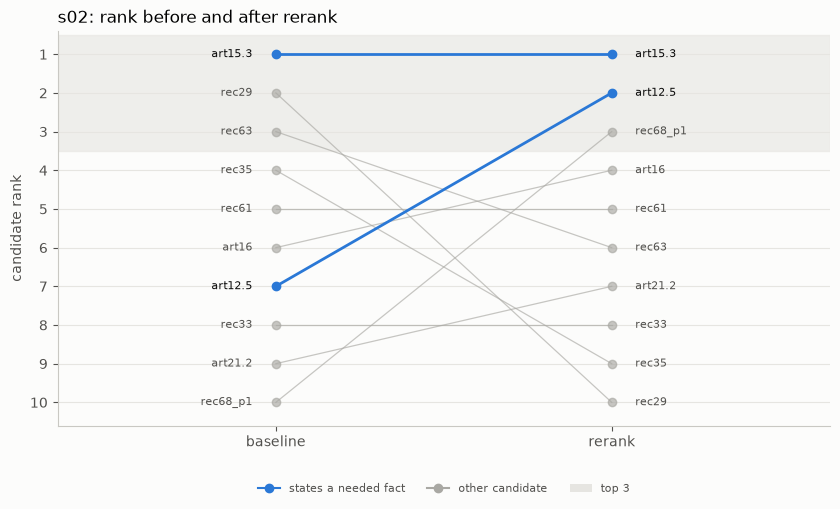

"answer 1 / baselineYou may have to pay a reasonable fee for copies beyond the first one. [Art. 15(3)]parsed citations: art15.3label: incompletefacts: missing,statedfirst copy being free is only implied, not stated; 'reasonable fee for copies beyond the first one' states the further-copies rule, administrative costs only explain what reasonable means","answer 2 / rerankYou may have to pay a fee for copies beyond the first one. [Art. 15(3)]parsed citations: art15.3label: incompletefacts: missing,missingfirst-copy free rule is not explicitly stated; additional fee omits reasonable and administrative-cost limits"


{'retrieval_improved': True, 'baseline_context_sufficient': False, 'rerank_context_sufficient': True, 'answer_improved': False, 'answer_worsened': True}

stress/s18 | exception | fixed
when does the right to data portability not apply?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
330,art20.2,"2. In exercising his or her right to data portability pursuant to paragraph 1, the",0.7123,1,5.0149,2,-1,
331,art20.1,1. The data subject shall have the right to receive the personal data concerning him,0.6940,2,4.0895,4,-2,
332,art20.4,4. The right referred to in paragraph 1 shall not adversely affect the rights and,0.6358,3,4.9672,3,0,
333,art20.3,3. The exercise of the right referred to in paragraph 1 of this Article shall,0.6303,4,7.6316,1,3,1
334,rec63,(63) A data subject should have the right of access to personal data which have,0.4982,5,-2.0866,8,-3,
335,art21.1,"1. The data subject shall have the right to object, on grounds relating to his",0.4770,6,-1.5015,6,0,
336,rec65,(65) A data subject should have the right to have personal data concerning him or,0.4651,7,-1.7312,7,0,
337,art16,The data subject shall have the right to obtain from the controller without undue delay,0.4610,8,-2.7867,9,-1,
338,rec68_p1,"(68) To further strengthen the control over his or her own data, where the processing",0.4585,9,3.6334,5,4,1
339,art15.1,1. The data subject shall have the right to obtain from the controller confirmation as,0.4560,10,-3.2205,10,0,


support moves: art20.3 #4 -> #1; rec68_p1 #9 -> #5


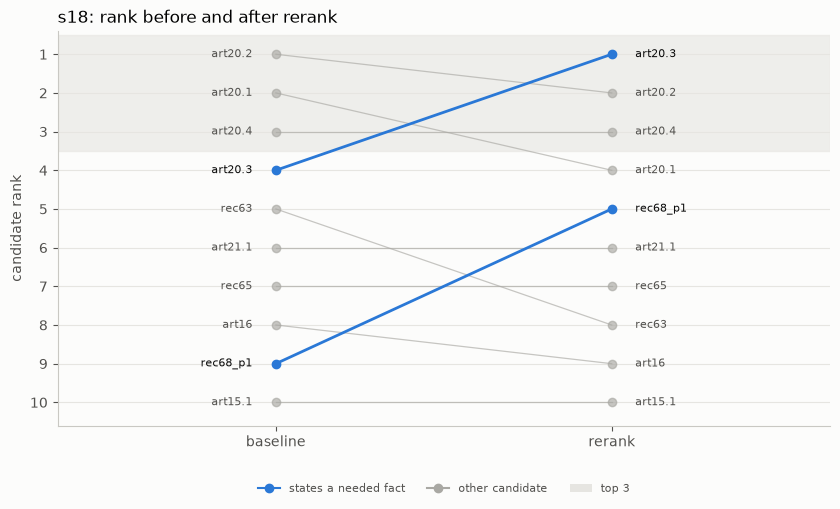

answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missingno registered support for a complete answer in the supplied passages,answer 2 / rerankNot found in the provided context.parsed citations: (none)label: refusedfacts: missingrefused despite registered support in its top three passages


{'retrieval_improved': True, 'baseline_context_sufficient': False, 'rerank_context_sufficient': True, 'answer_improved': False, 'answer_worsened': False}

stress/s21 | negation | fixed
when is a company not required to tell people their data was in a breach?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
360,art33.4,"4. Where, and in so far as, it is not possible to provide the information",0.4834,1,0.6272,5,-4,
361,art33.2,2. The processor shall notify the controller without undue delay after becoming aware of a,0.4713,2,-0.4087,7,-5,
362,art33.1,"1. In the case of a personal data breach, the controller shall without undue delay",0.4603,3,1.0527,4,-1,
363,rec85,"(85) A personal data breach may, if not addressed in an appropriate and timely manner,",0.4598,4,2.6770,2,2,
364,rec87,(87) It should be ascertained whether all appropriate technological protection and organisational measures have been,0.4273,5,-0.7984,8,-3,
365,art34.4,4. If the controller has not already communicated the personal data breach to the data,0.4191,6,1.8000,3,3,
366,art11.1,1. If the purposes for which a controller processes personal data do not or do,0.4110,7,-1.9592,10,-3,
367,art34.3,3. The communication to the data subject referred to in paragraph 1 shall not be,0.4108,8,3.2016,1,7,1
368,art34.1,1. When the personal data breach is likely to result in a high risk to,0.3982,9,-0.2197,6,3,
369,art33.5,"5. The controller shall document any personal data breaches, comprising the facts relating to the",0.3947,10,-1.7495,9,1,


support moves: art34.3 #8 -> #1


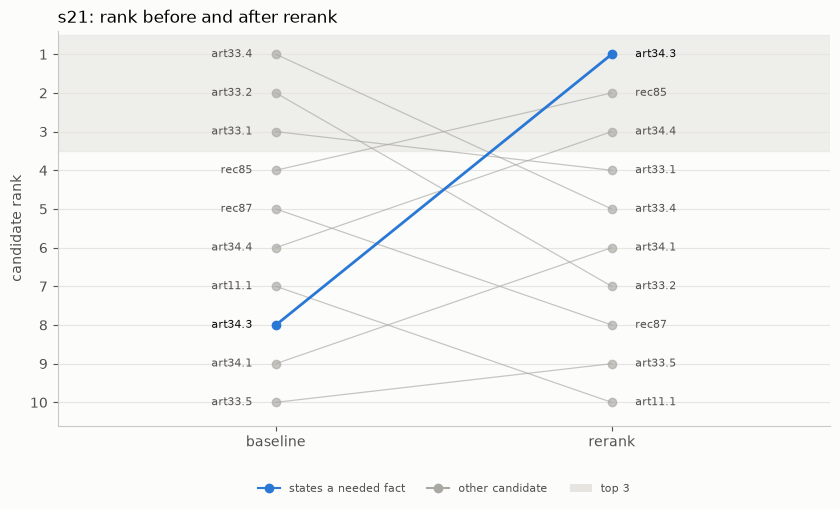

answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missingno registered support for a complete answer in the supplied passages,"answer 2 / rerankA company is not required to tell people their data was in a breach if any of the following conditions are met: * The company has implemented appropriate technical and organisational protection measures, and those measures were applied to the personal data affected by the personal data breach, in particular those that render the personal data unintelligible to any person who is not authorised to access it, such as encryption. [Art. 34(3)(a)] * The company has taken subsequent measures which ensure that the high risk to the rights and freedoms of data subjects referred to in paragraph 1 is no longer likely to materialise. [Art. 34(3)(b)] * It would involve disproportionate effort. In such a case, there shall instead be a public communication or similar measure whereby the data subjects are informed in an equally effective manner. [Art. 34(3)(c)]parsed citations: (none)label: correctfacts: statedall three conditions given; point-level citations refer to the supplied art34.3 despite being omitted by the frozen exact-label parser"


{'retrieval_improved': True, 'baseline_context_sufficient': False, 'rerank_context_sufficient': True, 'answer_improved': True, 'answer_worsened': False}

stress/s15 | buried | fixed
can eu countries make their own rules about how employers use workers' data?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
300,art45.8,8. The Commission shall publish in the Official Journal of the European Union and on,0.4529,1,-7.8123,7,-6,
301,art88.2,2. Those rules shall include suitable and specific measures to safeguard the data subject's human,0.4300,2,-5.0228,2,0,
302,art68.1,1. The European Data Protection Board (the ‘Board’) is hereby established as a body of,0.4208,3,-5.4595,3,0,
303,rec13,(13) In order to ensure a consistent level of protection for natural persons throughout the,0.4029,4,-7.8097,6,-2,
304,art71.1,1. The Board shall draw up an annual report regarding the protection of natural persons,0.3983,5,-8.3021,9,-4,
305,art68.5,5. The Commission shall have the right to participate in the activities and meetings of,0.3948,6,-7.3137,5,1,
306,art88.3,3. Each Member State shall notify to the Commission those provisions of its law which,0.3925,7,-10.9600,10,-3,
307,art49.5,"5. In the absence of an adequacy decision, Union or Member State law may, for",0.3901,8,-8.0008,8,0,
308,art88.1,"1. Member States may, by law or by collective agreements, provide for more specific rules",0.3897,9,-2.8859,1,8,1
309,art75.4,"4. Where appropriate, the Board and the European Data Protection Supervisor shall establish and publish",0.3873,10,-6.0408,4,6,


support moves: art88.1 #9 -> #1


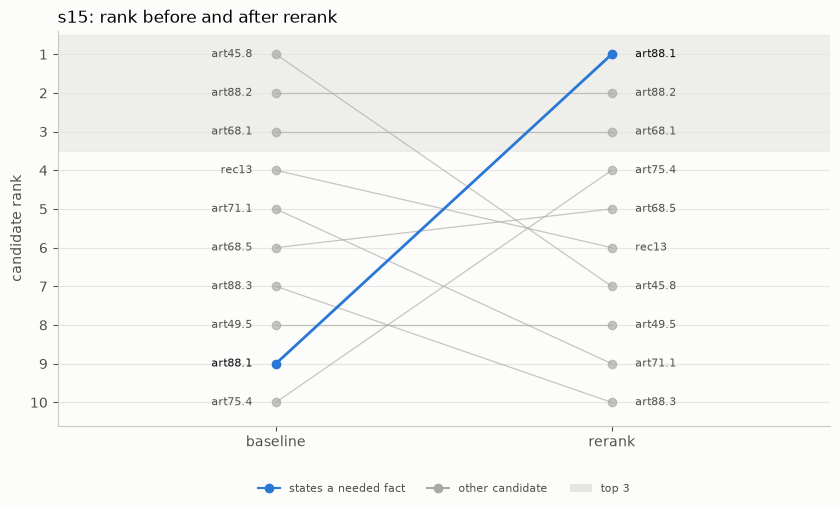

answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missingno registered support for a complete answer in the supplied passages,answer 2 / rerankYes. [Art. 88(1)]parsed citations: art88.1label: correctfacts: statedYes states the permission asked; law/collective-agreement mechanisms are not expanded; minimal binary answer accepted


{'retrieval_improved': True, 'baseline_context_sufficient': False, 'rerank_context_sufficient': True, 'answer_improved': True, 'answer_worsened': False}

stress/s17 | exception | hurt
is processing sensitive data like religion or health banned, or are there exceptions?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
320,rec54,(54) The processing of special categories of personal data may be necessary for reasons of,0.5126,1,-0.6040,2,-1,
321,art9.2_p1,2. Paragraph 1 shall not apply if one of the following applies: (a) the data,0.4986,2,-3.4942,6,-4,2
322,art18.2,"2. Where processing has been restricted under paragraph 1, such personal data shall, with the",0.4948,3,0.3131,1,2,
323,art32.2,2. In assessing the appropriate level of security account shall be taken in particular of,0.4792,4,-5.9825,8,-4,
324,rec53,(53) Special categories of personal data which merit higher protection should be processed for health-related,0.4542,5,-1.9996,3,2,
325,art9.2_p2,2. Paragraph 1 shall not apply if one of the following applies: (g) processing is,0.4483,6,-2.9348,5,1,2
326,art7.1,"1. Where processing is based on consent, the controller shall be able to demonstrate that",0.4476,7,-6.3071,9,-2,
327,art18.1,1. The data subject shall have the right to obtain from the controller restriction of,0.4438,8,-5.8716,7,1,
328,art91.1,"1. Where in a Member State, churches and religious associations or communities apply, at the",0.4431,9,-2.4026,4,5,
329,rec43,"(43) In order to ensure that consent is freely given, consent should not provide a",0.4396,10,-8.1400,10,0,


support moves: art9.2_p1 #2 -> #6; art9.2_p2 #6 -> #5


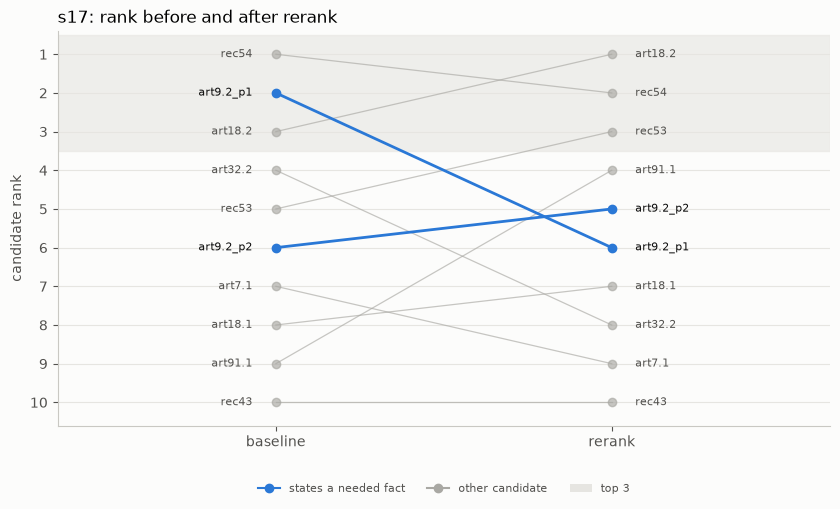

"answer 1 / baselineProcessing sensitive data like religion or health is not banned, there are exceptions. [Art. 9(2)]parsed citations: (none)label: wrongfacts: wrong,stated'not banned' contradicts the general prohibition, its own art 9(2) passage says 'the prohibition referred to in paragraph 1'; exceptions stated","answer 2 / rerankNot found in the provided context.parsed citations: (none)label: refusedfacts: missing,missingno registered support for a complete answer in the supplied passages"


{'retrieval_improved': False, 'baseline_context_sufficient': False, 'rerank_context_sufficient': False, 'answer_improved': False, 'answer_worsened': False}

eval/ex01 | exception | same, missing
What is my right to get personal data deleted, and can deletion be refused when the data is needed to defend a legal claim?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
40,rec85,"(85) A personal data breach may, if not addressed in an appropriate and timely manner,",0.4787,1,-2.3543,4,-3,
41,art33.4,"4. Where, and in so far as, it is not possible to provide the information",0.4290,2,-4.5772,7,-5,
42,rec68_p2,"(68) (continued) Furthermore, that right should not prejudice the right of the data subject to",0.4099,3,0.0266,2,1,
43,art33.2,2. The processor shall notify the controller without undue delay after becoming aware of a,0.4046,4,-5.3716,9,-5,
44,rec61,(61) The information in relation to the processing of personal data relating to the data,0.3863,5,-3.6641,5,0,
45,art21.6,6. Where personal data are processed for scientific or historical research purposes or statistical purposes,0.3747,6,-0.9811,3,3,
46,rec28,(28) The application of pseudonymisation to personal data can reduce the risks to the data,0.3744,7,-4.7384,8,-1,
47,art4.12,For the purposes of this Regulation: (12) ‘personal data breach’ means a breach of security,0.3725,8,-3.8856,6,2,
48,art16,The data subject shall have the right to obtain from the controller without undue delay,0.3633,9,0.3375,1,8,
49,art76.1,"1. The discussions of the Board shall be confidential where the Board deems it necessary,",0.3609,10,-10.2568,10,0,


support moves: none in the 10


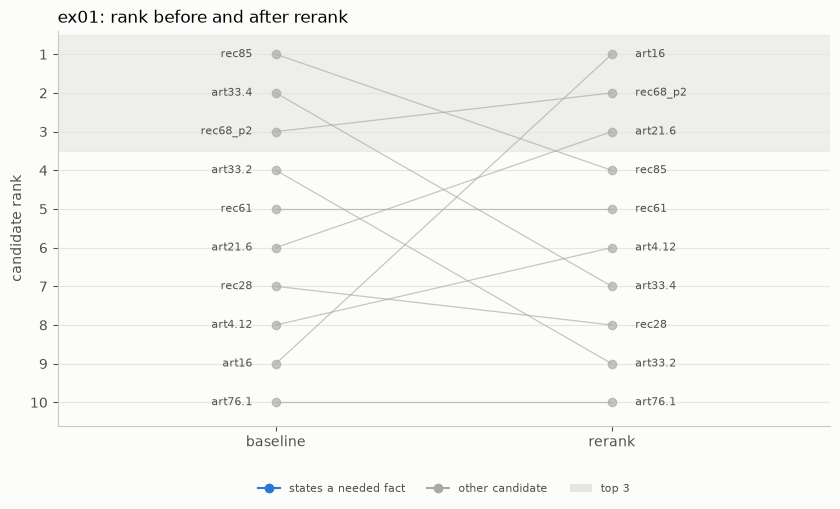

"answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missing,missingno registered support for a complete answer in the supplied passages","answer 2 / rerankNot found in the provided context.parsed citations: (none)label: refusedfacts: missing,missingno registered support for a complete answer in the supplied passages"


{'retrieval_improved': False, 'baseline_context_sufficient': False, 'rerank_context_sufficient': False, 'answer_improved': False, 'answer_worsened': False}

stress/s13 | buried | same, missing
what is the maximum fine for breaking the rules on children's consent?


,chunk_id,starts,cosine,bi_rank,ce_score,ce_rank,move,supports_facts
280,art8.1,"1. Where point (a) of Article 6(1) applies, in relation to the offer of information",0.4735,1,-4.1785,1,0,
281,art8.3,3. Paragraph 1 shall not affect the general contract law of Member States such as,0.4371,2,-4.5716,2,0,
282,art8.2,2. The controller shall make reasonable efforts to verify in such cases that consent is,0.4258,3,-5.3682,3,0,
283,art7.4,"4. When assessing whether consent is freely given, utmost account shall be taken of whether,",0.4158,4,-9.4195,7,-3,
284,rec171,(171) Directive 95/46/EC should be repealed by this Regulation. Processing already under way on the,0.3528,5,-10.1161,9,-4,
285,art4.11,For the purposes of this Regulation: (11) ‘consent’ of the data subject means any freely,0.3398,6,-9.7251,8,-2,
286,art7.1,"1. Where processing is based on consent, the controller shall be able to demonstrate that",0.3343,7,-9.2143,5,2,
287,rec32,"(32) Consent should be given by a clear affirmative act establishing a freely given, specific,",0.3246,8,-9.2616,6,2,
288,art7.3,3. The data subject shall have the right to withdraw his or her consent at,0.2956,9,-8.3241,4,5,
289,rec43,"(43) In order to ensure that consent is freely given, consent should not provide a",0.2924,10,-10.1716,10,0,


support moves: none in the 10


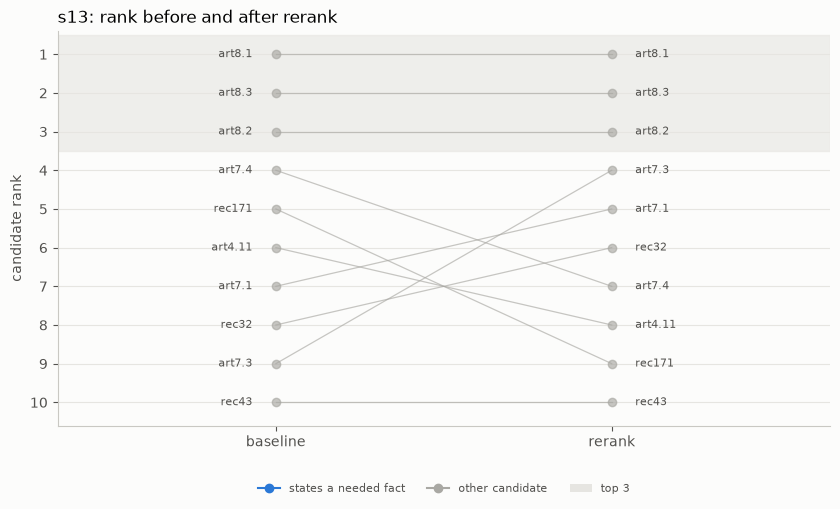

answer 1 / baselineNot found in the provided context.parsed citations: (none)label: refusedfacts: missingno registered support for a complete answer in the supplied passages,answer 2 / rerankNot found in the provided context.parsed citations: (none)label: refusedfacts: missingno registered support for a complete answer in the supplied passages


{'retrieval_improved': False, 'baseline_context_sufficient': False, 'rerank_context_sufficient': False, 'answer_improved': False, 'answer_worsened': False}


,query_id,outcome,retrieval_improved,baseline_context_sufficient,rerank_context_sufficient,answer_improved,answer_worsened
0,kt02,fixed,True,False,True,True,False
1,s02,fixed,True,False,True,False,True
2,s18,fixed,True,False,True,False,False
3,s21,fixed,True,False,True,True,False
4,s15,fixed,True,False,True,True,False
5,s17,hurt,False,False,False,False,False
6,ex01,"same, missing",False,False,False,False,False
7,s13,"same, missing",False,False,False,False,False


In [26]:
#same look as the chunk length histogram
def style_axis(axis) -> None:
    axis.set_facecolor(SURFACE)
    axis.tick_params(colors=MUTED)
    axis.xaxis.label.set_color(MUTED)
    axis.yaxis.label.set_color(MUTED)
    axis.title.set_color(INK)
    axis.grid(axis="y", color=GRID, linewidth=0.8)
    axis.set_axisbelow(True)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(AXIS)


def rank_shift_plot(table: pd.DataFrame, query_id: str) -> None:
    #one line per candidate, left = bi-encoder rank, right = cross-encoder rank
    figure, axis = plt.subplots(figsize=(8.5, 5.2), facecolor=SURFACE)
    style_axis(axis)
    axis.axhspan(0.5, TOP_N + 0.5, color=GRID, alpha=0.6)  # the top 3 zone
    for row in table.itertuples():
        supported = bool(str(row.supports_facts))
        axis.plot([0, 1], [row.bi_rank, row.ce_rank], marker="o", color=SERIES if supported else QUIET,
                  linewidth=2 if supported else 0.9, alpha=1 if supported else 0.65, zorder=3 if supported else 2)
        axis.text(-0.07, row.bi_rank, row.chunk_id, ha="right", va="center", fontsize=8, color=INK if supported else MUTED)
        axis.text(1.07, row.ce_rank, row.chunk_id, ha="left", va="center", fontsize=8, color=INK if supported else MUTED)
    axis.set(xlim=(-0.65, 1.65), ylim=(10.6, 0.4), xticks=[0, 1], xticklabels=["baseline", "rerank"],
             yticks=range(1, 11), ylabel="candidate rank")  # rank 1 on top
    axis.set_title(f"{query_id}: rank before and after rerank", loc="left")
    handles = [Line2D([0], [0], color=SERIES, marker="o", label="states a needed fact"),
               Line2D([0], [0], color=QUIET, marker="o", label="other candidate"),
               Patch(facecolor=GRID, label="top 3")]
    axis.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False,
                labelcolor=MUTED, fontsize=8)
    figure.tight_layout()
    figure.savefig(FIGURES / f"rank_shift_{query_id}.png", dpi=200, facecolor=SURFACE)
    plt.show()
    plt.close(figure)


def answer_improved(before: pd.Series, after: pd.Series) -> bool:
    #more facts without more errors, or fewer errors without losing facts
    no_loss = after.facts_stated >= before.facts_stated and after.wrong_facts <= before.wrong_facts and after.unsupported <= before.unsupported
    gain = after.facts_stated > before.facts_stated or after.wrong_facts < before.wrong_facts or after.unsupported < before.unsupported
    return bool(no_loss and gain)


def show_answers(before: pd.Series, after: pd.Series) -> None:
    #answer 1 and answer 2 side by side, html so long answers wrap
    cells = []
    for name, row in (("answer 1 / baseline", before), ("answer 2 / rerank", after)):
        cells.append("<td style='width:50%;vertical-align:top;padding:12px'>" +
                     f"<b>{name}</b><p style='white-space:pre-wrap'>{html.escape(row.answer)}</p>" +
                     f"<p>parsed citations: {html.escape(row.cited or '(none)')}<br>label: {row.overall}<br>" +
                     f"facts: {row.fact_labels}</p><p>{html.escape(row.note)}</p></td>")
    display(HTML("<table style='width:100%;table-layout:fixed'><tr>" + "".join(cells) + "</tr></table>"))


case_rows = []
assessment_lookup = assessed.set_index(["set", "query_id", "pipeline"])
for set_name, query_id in SHOWCASES:
    query = QUERY_LOOKUP[(set_name, query_id)]
    table = candidates[(candidates.set == set_name) & (candidates.query_id == query_id)].copy()
    measured = metrics[(metrics.set == set_name) & (metrics.query_id == query_id)].iloc[0]
    before = assessment_lookup.loc[(set_name, query_id, "baseline")]
    after = assessment_lookup.loc[(set_name, query_id, "rerank")]
    print(f"\n{set_name}/{query_id} | {query['category']} | {measured.outcome}\n{query['query']}")
    #top 10 with both ranks, move > 0 = the cross-encoder pulled it up
    table["move"] = table.bi_rank - table.ce_rank
    table["starts"] = table.chunk_id.map(lambda chunk_id: " ".join(CHUNK_TEXT[chunk_id].split("\n", 1)[1].split()[:15]))
    display(table[["chunk_id", "starts", "cosine", "bi_rank", "ce_score", "ce_rank", "move", "supports_facts"]])
    print("support moves:", measured.support_moves)
    rank_shift_plot(table, query_id)
    show_answers(before, after)
    #the three observations, kept apart on purpose
    observations = {"retrieval_improved": bool(measured["rerank_facts@3"] > measured["baseline_facts@3"]),
                    "baseline_context_sufficient": bool(measured["baseline_sufficient@3"]),
                    "rerank_context_sufficient": bool(measured["rerank_sufficient@3"]),
                    "answer_improved": answer_improved(before, after), "answer_worsened": answer_improved(after, before)}
    print(observations)
    case_rows.append({"set": set_name, "query_id": query_id, "category": query["category"], "query": query["query"],
                      "outcome": measured.outcome, "pool_gap": measured.pool_gap, "support_moves": measured.support_moves,
                      **observations, **{f"{name}_{key}": row[key] for name, row in (("baseline", before), ("rerank", after))
                                        for key in ("context", "answer", "cited", "overall", "fact_labels", "facts_stated", "unsupported", "note")}})

case_studies = pd.DataFrame(case_rows)
case_studies.to_csv(RESULTS / "case_studies.csv", index=False, lineterminator="\n")
display(case_studies[["query_id", "outcome", "retrieval_improved", "baseline_context_sufficient", "rerank_context_sufficient",
                      "answer_improved", "answer_worsened"]])

## where rerank didn't help

from the case studies: the `hurt` one, the pool gaps, and the ones where retrieval got better but the answer didn't.
then every answer where refusing and having support don't line up: refused although its top 3 had a supporting chunk,
or answered although its top 3 had none.
"support" = the ids in the label files, which aren't exhaustive. e.g. s17's reranked top 3 has rec53 and rec54 (recitals about
health data) that its support list doesn't name

In [27]:
#hurt, pool gap, or better retrieval without a better answer
not_helped = case_studies[(case_studies.outcome == "hurt") | case_studies.pool_gap.astype(bool) |
                          (case_studies.retrieval_improved & ~case_studies.answer_improved)]
display(not_helped[["query_id", "outcome", "pool_gap", "support_moves", "baseline_overall", "rerank_overall"]])

#refused with support in its own top 3, or answered with none
diagnostics = []
for row in assessed.itertuples():
    query = QUERY_LOOKUP[(row.set, row.query_id)]
    covered = score(query, row.context.split(","))  # the 3 passages that answer actually got
    any_support = bool(covered["hit@3"])
    if (row.refused and any_support) or (not row.refused and not any_support):
        diagnostics.append({"set": row.set, "query_id": row.query_id, "pipeline": row.pipeline,
                            "registered_support_in_context": any_support, "refused": row.refused,
                            "unsupported": row.unsupported, "overall": row.overall, "answer": row.answer, "note": row.note})
answer_diagnostics = pd.DataFrame(diagnostics)
answer_diagnostics.to_csv(RESULTS / "answer_diagnostics.csv", index=False, lineterminator="\n")
display(answer_diagnostics)
print("refused although the top 3 had support:", int((answer_diagnostics.refused & answer_diagnostics.registered_support_in_context).sum()))
print("answered with no support in the top 3:", int((~answer_diagnostics.refused & ~answer_diagnostics.registered_support_in_context).sum()))

,query_id,outcome,pool_gap,support_moves,baseline_overall,rerank_overall
1,s02,fixed,False,art15.3 #1 -> #1; art12.5 #7 -> #2,incomplete,incomplete
2,s18,fixed,False,art20.3 #4 -> #1; rec68_p1 #9 -> #5,refused,refused
5,s17,hurt,True,art9.2_p1 #2 -> #6; art9.2_p2 #6 -> #5,wrong,refused
6,ex01,"same, missing",True,none in the 10,refused,refused
7,s13,"same, missing",True,none in the 10,refused,refused


,set,query_id,pipeline,registered_support_in_context,refused,unsupported,overall,answer,note
0,eval,kt04,rerank,False,False,True,wrong,A company has to respond to your request to see your personal data within one month. [Art. 12(4)] \n\nIt can take l...,one-month claim is partial; art12.4 concerns not taking action and does not authorise the claimed extension; complex...
1,stress,s05,rerank,False,False,True,wrong,"[Art. 21(3)] \nYes. If you object to processing for direct marketing purposes, the personal data shall no longer be...","a bare Yes to 'do they always have to stop' says they always must, which contradicts the compelling grounds / legal ..."
2,stress,s08,rerank,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
3,stress,s09,baseline,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
4,stress,s09,rerank,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
5,stress,s12,rerank,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
6,stress,s18,rerank,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
7,stress,s19,rerank,False,False,True,wrong,Yes. [Art. 57(4)],"the Yes asserts the company can refuse repeated requests, which matches the fact; but it cites art 57(4), a supervis..."
8,stress,s22,baseline,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages
9,stress,s23,baseline,True,True,False,refused,Not found in the provided context.,refused despite registered support in its top three passages


refused although the top 3 had support: 8
answered with no support in the top 3: 3


## negation demo

two question pairs that only differ by "not", each scored against the rule chunk and its exception chunk.
`bi_cosine` = bi-encoder cosine, `ce_score` = cross-encoder logit, `query_pair_cosine` = how close the bi-encoder thinks the two
questions are. the numbers are shown as they come out

,pair,variant,query,chunk_id,bi_cosine,ce_score,query_pair_cosine
0,breach,positive,when does a company have to tell people about a data breach?,art34.1,0.4008,1.2438,0.9264
1,breach,positive,when does a company have to tell people about a data breach?,art34.3,0.2993,-0.5259,0.9264
2,breach,not,when does a company not have to tell people about a data breach?,art34.1,0.3840,-0.0012,0.9264
3,breach,not,when does a company not have to tell people about a data breach?,art34.3,0.3045,0.8222,0.9264
4,erasure,positive,when do i have the right to have my data erased?,art17.1,0.5895,4.4660,0.9623
5,erasure,positive,when do i have the right to have my data erased?,art17.3,0.3826,-8.1440,0.9623
6,erasure,not,when do i not have the right to have my data erased?,art17.1,0.5649,3.4854,0.9623
7,erasure,not,when do i not have the right to have my data erased?,art17.3,0.3778,-8.5899,0.9623


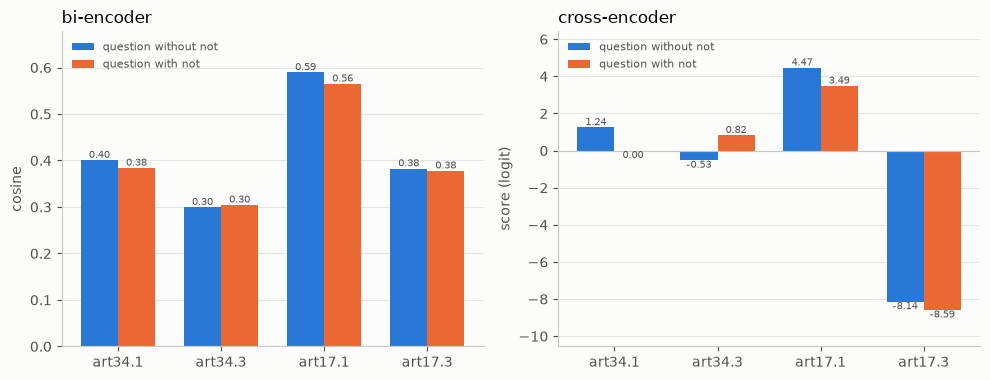

In [28]:
negation_rows = []
for name, positive, negative, pair_chunks in NEGATION_PAIRS:
    assert negative.replace(" not ", " ") == positive  # only "not" differs
    query_vectors = bi_encoder.encode([positive, negative], convert_to_numpy=True)
    chunk_vectors_pair = bi_encoder.encode([CHUNK_TEXT[chunk_id] for chunk_id in pair_chunks], convert_to_numpy=True)
    paired = [(query, CHUNK_TEXT[chunk_id]) for query in (positive, negative) for chunk_id in pair_chunks]
    ce_scores = cross_encoder.predict(paired, batch_size=4, convert_to_numpy=True)  # [pos x rule, pos x exception, not x rule, not x exception]
    for query_number, query in enumerate((positive, negative)):
        for chunk_number, chunk_id in enumerate(pair_chunks):
            negation_rows.append({"pair": name, "variant": "positive" if query_number == 0 else "not", "query": query, "chunk_id": chunk_id,
                                  "bi_cosine": float(query_vectors[query_number] @ chunk_vectors_pair[chunk_number]),
                                  "ce_score": float(ce_scores[query_number * 2 + chunk_number]),
                                  "query_pair_cosine": float(query_vectors[0] @ query_vectors[1])})
negation = pd.DataFrame(negation_rows)
negation.to_csv(RESULTS / "negation_demo.csv", index=False, lineterminator="\n")
display(negation.round(4))

#blue = question without "not", orange = with "not", one group per chunk
chart_chunks = [chunk_id for *_, pair_chunks in NEGATION_PAIRS for chunk_id in pair_chunks]
figure, axes = plt.subplots(1, 2, figsize=(10, 3.9), facecolor=SURFACE)
for axis, value, title, unit in zip(axes, ("bi_cosine", "ce_score"), ("bi-encoder", "cross-encoder"), ("cosine", "score (logit)")):
    style_axis(axis)
    axis.axhline(0, color=AXIS, linewidth=0.8)  # some cross-encoder scores sit right at 0
    for offset, variant, color in ((-0.18, "positive", SERIES), (0.18, "not", ORANGE)):
        values = negation[negation.variant == variant].set_index("chunk_id").loc[chart_chunks, value]
        axis.bar(np.arange(len(chart_chunks)) + offset, values, width=0.36, color=color, label=f"question {'without' if variant == 'positive' else 'with'} not")
        for position, number in enumerate(values):
            axis.text(position + offset, number, f"{0 if abs(number) < 0.005 else number:.2f}", ha="center", va="bottom" if number >= 0 else "top", fontsize=7, color=MUTED)
    axis.set(xticks=range(len(chart_chunks)), xticklabels=chart_chunks, ylabel=unit)
    axis.set_title(title, loc="left")
    axis.margins(y=0.15)
    axis.legend(frameon=False, labelcolor=MUTED, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "negation.png", dpi=200, facecolor=SURFACE)
plt.show()
plt.close(figure)
RUN_INFO["answer_labels"] = {"file": "data/answer_labels.yaml", "answers": len(assessed),
                             "sha256": hashlib.sha256((DATA / "answer_labels.yaml").read_bytes()).hexdigest(),
                             "status": "first pass + a second pass on 6 disputed answers, still open to a human check"}
RUN_INFO["showcases"] = [f"{set_name}/{query_id}" for set_name, query_id in SHOWCASES]
save_run_info()

## latency

config: encoders on cuda, faiss on cpu (faiss-cpu), gemma2 split between cpu and gpu by ollama (it doesn't fully fit in 8 gb here)
- retrieval timed on its own: 5 warm-ups, then the 16 eval questions x 10 repeats. `query_encode` (incl. tensor -> numpy),
  `faiss_search` (the search call only), `cross_encoder` (tokenise + score the 10 pairs + sort)
- live requests: each eval question once per pipeline, a fresh message each time, who goes first flips every question.
  retrieval inside these is timed too (`*_live_retrieval`). it's slower than the isolated trials since it runs right between llm calls
  on the same gpu. `rerank_cost_live` = rerank minus baseline retrieval for the same question, inside those live requests
- `prefill` / `decode` / `load` are ollama's own timers. `prompt_eval_count` is what ollama reports, reusing a prompt prefix makes
  prefill faster without changing that count
- a few live answers can come out slightly different from the cached ones (`matches_cached_answer`), those timings belong to the new text
- p95 over 16 live requests is basically the slowest one

In [29]:
LATENCY_CONFIG = f"encoders on {DEVICE}, faiss on cpu"
answers_cache_sha = hashlib.sha256(ANSWERS_FILE.read_bytes()).hexdigest()


def time_retrieval(query: str) -> dict:
    #same steps as retrieve() + rerank(), with a timer around each stage
    sync()
    started = time.perf_counter()
    vector = bi_encoder.encode([query], convert_to_numpy=True).astype("float32")
    sync()
    encode_ms = (time.perf_counter() - started) * 1000
    started = time.perf_counter()
    scores, positions = index.search(vector, TOP_K)
    search_ms = (time.perf_counter() - started) * 1000  # the search call only
    table = pd.DataFrame({"chunk_id": chunks.chunk_id.values[positions[0]], "cosine": scores[0], "bi_rank": np.arange(1, TOP_K + 1)})
    sync()
    started = time.perf_counter()
    rerank(query, table)
    sync()
    rerank_ms = (time.perf_counter() - started) * 1000  # tokenisation, scores, numpy conversion, sort
    return {"query_encode": encode_ms, "faiss_search": search_ms, "cross_encoder": rerank_ms,
            "baseline_retrieval": encode_ms + search_ms, "rerank_retrieval": encode_ms + search_ms + rerank_ms}


#warm-ups, not kept
for warmup in range(TIMING_WARMUPS):
    time_retrieval(eval_queries[warmup % len(eval_queries)]["query"])

#isolated retrieval timings, 16 questions x 10
retrieval_timings = []
for repetition in range(TIMING_REPEATS):
    for query in eval_queries:
        retrieval_timings.append({"query_id": query["id"], "repetition": repetition + 1, **time_retrieval(query["query"])})
retrieval_timings = pd.DataFrame(retrieval_timings)
retrieval_timings.to_csv(RESULTS / "latency_retrieval.csv", index=False, lineterminator="\n")
assert len(retrieval_timings) == len(eval_queries) * TIMING_REPEATS


def time_live_pipeline(query: dict, pipeline: str, called_first: bool) -> dict:
    #one real request: retrieval (+ rerank) -> prompt -> gemma2, timed end to end
    sync()
    end_to_end_started = time.perf_counter()
    table = retrieve(query["query"])
    if pipeline == "rerank":
        table = rerank(query["query"], table)
    sync()
    retrieval_ms = (time.perf_counter() - end_to_end_started) * 1000
    context = top_ids(table, "bi_rank" if pipeline == "baseline" else "ce_rank")
    cached = answer_lookup.loc[("eval", query["id"], pipeline)]
    assert context == cached.context.split(",")  # same passages as the labelled answer
    prompt = build_prompt(query["query"], context)
    assert prompt == cached.prompt
    started = time.perf_counter()
    response = ollama.chat(model=LLM, messages=[{"role": "user", "content": prompt}], options=LLM_OPTIONS, keep_alive="30m")
    wall_ms = (time.perf_counter() - started) * 1000
    end_to_end_ms = (time.perf_counter() - end_to_end_started) * 1000
    return {"query_id": query["id"], "pipeline": pipeline, "called_first": called_first,
            "retrieval_ms": retrieval_ms, "llm_wall_ms": wall_ms, "end_to_end_ms": end_to_end_ms,
            "load_ms": response.load_duration / 1e6, "prefill_ms": response.prompt_eval_duration / 1e6,
            "decode_ms": response.eval_duration / 1e6, "prompt_eval_count": response.prompt_eval_count,
            "output_tokens": response.eval_count, "decode_tokens_per_second": response.eval_count / (response.eval_duration / 1e9),
            "prompt_chars": len(prompt), "done_reason": response.done_reason,
            "answer_sha": answer_sha(response.message.content.strip()),
            "matches_cached_answer": answer_sha(response.message.content.strip()) == cached.answer_sha}  # timing only, never saved over the cache


#live requests, who goes first flips every question
llm_timings = []
for number, query in enumerate(eval_queries):
    order = ("baseline", "rerank") if number % 2 == 0 else ("rerank", "baseline")
    for position, pipeline in enumerate(order):
        llm_timings.append(time_live_pipeline(query, pipeline, position == 0))
    print(f"live timing {number + 1}/{len(eval_queries)}: {query['id']}", flush=True)
llm_timings = pd.DataFrame(llm_timings)
llm_timings["placement"] = ollama_placement(LLM)
llm_timings.to_csv(RESULTS / "latency_llm.csv", index=False, lineterminator="\n")
assert hashlib.sha256(ANSWERS_FILE.read_bytes()).hexdigest() == answers_cache_sha, "labelled answer cache changed"
assert len(llm_timings) == 2 * len(eval_queries)


def timing_summary(stage: str, values: pd.Series) -> dict:
    return {"stage": stage, "n": len(values), "mean_ms": float(values.mean()), "median_ms": float(values.median()),
            "p95_ms": float(values.quantile(0.95))}


#isolated stages
latency_rows = [timing_summary(stage, retrieval_timings[stage]) for stage in
                ("query_encode", "faiss_search", "cross_encoder", "baseline_retrieval", "rerank_retrieval")]
#retrieval inside the live requests, plus what rerank adds there (rerank minus baseline for the same question)
live_retrieval = llm_timings.pivot(index="query_id", columns="pipeline", values="retrieval_ms")
for pipeline in ("baseline", "rerank"):
    latency_rows.append(timing_summary(f"{pipeline}_live_retrieval", live_retrieval[pipeline]))
latency_rows.append(timing_summary("rerank_cost_live", live_retrieval.rerank - live_retrieval.baseline))
#llm + end to end per pipeline
for pipeline in ("baseline", "rerank"):
    values = llm_timings[llm_timings.pipeline == pipeline]
    for column in ("llm_wall_ms", "prefill_ms", "decode_ms", "end_to_end_ms"):
        latency_rows.append(timing_summary(f"{pipeline}_{column}", values[column]))
latency = pd.DataFrame(latency_rows)
latency.to_csv(RESULTS / "latency.csv", index=False, lineterminator="\n")
latency_means = latency.set_index("stage").mean_ms

#what the reranker costs, each share uses numbers from the same kind of measurement
rerank_cost = {
    "isolated_ms": float(latency_means.cross_encoder),
    "isolated_pct_of_baseline_retrieval": float(100 * latency_means.cross_encoder / latency_means.baseline_retrieval),
    "live_ms": float(latency_means.rerank_cost_live),
    "live_pct_of_rerank_end_to_end": float(100 * latency_means.rerank_cost_live / latency_means.rerank_end_to_end_ms),
}
display(latency.round(3))
display(llm_timings.groupby("pipeline")[["prompt_eval_count", "output_tokens", "decode_tokens_per_second", "load_ms"]].mean().round(2))
print("config:", LATENCY_CONFIG, "| Ollama:", ollama_placement(LLM))
print("rerank cost:", {name: round(value, 2) for name, value in rerank_cost.items()}, "| one-off corpus encode:", RUN_INFO["index"]["build_seconds"], "s")
print("live outputs matching labelled cache:", int(llm_timings.matches_cached_answer.sum()), "/", len(llm_timings))

live timing 1/16: kt01


live timing 2/16: kt02


live timing 3/16: kt03


live timing 4/16: kt04


live timing 5/16: ex01


...

live timing 15/16: bd03


live timing 16/16: bd04


,stage,n,mean_ms,median_ms,p95_ms
0,query_encode,160,5.447,5.057,7.816
1,faiss_search,160,0.086,0.082,0.112
2,cross_encoder,160,16.561,15.030,21.735
3,baseline_retrieval,160,5.533,5.149,7.934
4,rerank_retrieval,160,22.094,20.561,29.095
5,baseline_live_retrieval,16,170.496,145.523,351.523
6,rerank_live_retrieval,16,389.959,377.808,691.213
7,rerank_cost_live,16,219.463,166.366,549.277
8,baseline_llm_wall_ms,16,5805.208,5581.437,10156.259
9,baseline_prefill_ms,16,3031.714,3164.550,5588.066


,prompt_eval_count,output_tokens,decode_tokens_per_second,load_ms
pipeline,,,,
baseline,442.69,30.56,20.66,5.62
rerank,469.94,50.38,19.69,7.28


config: encoders on cuda, faiss on cpu | Ollama: 24%/76% CPU/GPU
rerank cost: {'isolated_ms': 16.56, 'isolated_pct_of_baseline_retrieval': 299.3, 'live_ms': 219.46, 'live_pct_of_rerank_end_to_end': 3.04} | one-off corpus encode: 2.23 s
live outputs matching labelled cache: 27 / 32


end to end differs between the pipelines mostly because the prompts and answers differ in length (different passages in, different
answer out), not because of the reranker. the reranker's own cost is `rerank_cost_live`

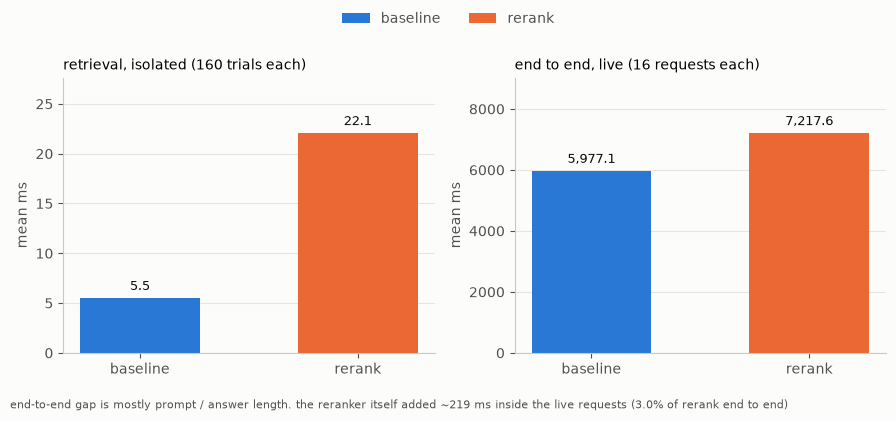

In [30]:
#left = retrieval alone, right = whole live request. different scales, so two panels instead of one axis
figure, axes = plt.subplots(1, 2, figsize=(9, 4.1), facecolor=SURFACE)
for axis, stages, title in zip(axes, (("baseline_retrieval", "rerank_retrieval"),
                                    ("baseline_end_to_end_ms", "rerank_end_to_end_ms")),
                               ("retrieval, isolated (160 trials each)", "end to end, live (16 requests each)")):
    style_axis(axis)
    values = [float(latency_means[stage]) for stage in stages]
    axis.bar([0, 1], values, color=[SERIES, ORANGE], width=0.55)
    axis.set(xticks=[0, 1], xticklabels=["baseline", "rerank"], ylabel="mean ms", ylim=(0, max(values) * 1.25))
    axis.set_title(title, loc="left", fontsize=10)
    for position, value in enumerate(values):
        axis.text(position, value + max(values) * 0.035, f"{value:,.1f}", ha="center", fontsize=9, color=INK)
figure.legend(handles=[Patch(facecolor=SERIES, label="baseline"), Patch(facecolor=ORANGE, label="rerank")],
              loc="upper center", ncol=2, frameon=False, labelcolor=MUTED)
figure.text(0.01, 0.01, f"end-to-end gap is mostly prompt / answer length. the reranker itself added ~{rerank_cost['live_ms']:.0f} ms "
            f"inside the live requests ({rerank_cost['live_pct_of_rerank_end_to_end']:.1f}% of rerank end to end)", fontsize=8, color=MUTED)
figure.tight_layout(rect=(0, 0.05, 1, 0.9))
figure.savefig(FIGURES / "latency.png", dpi=200, facecolor=SURFACE)
plt.show()
plt.close(figure)
RUN_INFO["latency"] = {"config": LATENCY_CONFIG, "warmups": TIMING_WARMUPS, "retrieval_repetitions": TIMING_REPEATS,
                       "retrieval_trials": len(retrieval_timings), "llm_requests": len(llm_timings),
                       "ollama_placement": ollama_placement(LLM), "generation_order": "alternates by query",
                       "cache_state": "warm model, ollama may reuse a prompt prefix", "rerank_cost": rerank_cost}
save_run_info()

## scaling

why not run the cross-encoder over everything from the start: it has to score every (query, chunk) pair at query time, nothing
about a chunk can be computed ahead. the bi-encoder did its 607 chunks once, before any question.

measured at 607 chunks (all 607 pairs per eval question, batches of 32 = 607 pair evaluations, not 607 separate calls).
bigger sizes are extrapolated, not run
- cross-encoder ≈ chunks / measured pairs per second
- baseline = one query encode + a flat scan that grows linearly with the chunk count. an ann index like hnsw would skip the full scan

the bi-encoder side reuses the isolated latency trials above. timing it right after a 607-pair batch made it look ~2x slower

In [31]:
#bi-encoder side from the isolated trials: query encode + the search call
mean_encode = float(latency_means.query_encode)
mean_search = float(latency_means.faiss_search)

#cross-encoder over all 607 chunks for every eval question
all_chunk_text = chunks.text.tolist()
cross_encoder.predict([(eval_queries[0]["query"], text) for text in all_chunk_text[:SCALING_BATCH_SIZE]],
                      batch_size=SCALING_BATCH_SIZE, convert_to_numpy=True)  # warm-up batch, not timed
sync()
scaling_trials = []
for query in eval_queries:
    #every (query, chunk) pair has to fit in 512 tokens
    assert len(cross_encoder.tokenizer(query["query"])["input_ids"]) - 1 + max(CHUNK_CE_TOKENS.values()) <= cross_encoder.max_seq_length
    pairs = [(query["query"], text) for text in all_chunk_text]
    sync()
    started = time.perf_counter()
    scores = cross_encoder.predict(pairs, batch_size=SCALING_BATCH_SIZE, convert_to_numpy=True)
    sync()
    score_ms = (time.perf_counter() - started) * 1000
    assert len(scores) == len(chunks) and np.isfinite(scores).all()
    np.argsort(-scores, kind="stable")  # full ranking, tiny next to scoring
    rank_ms = (time.perf_counter() - started) * 1000
    scaling_trials.append({"query_id": query["id"], "chunks": len(chunks), "batch_size": SCALING_BATCH_SIZE,
                           "cross_encoder_ms": score_ms, "cross_encoder_with_sort_ms": rank_ms,
                           "pairs_per_second": len(chunks) / (score_ms / 1000)})
    print(f"full-corpus timing {len(scaling_trials)}/{len(eval_queries)}: {query['id']}", flush=True)
scaling_trials = pd.DataFrame(scaling_trials)
scaling_trials.to_csv(RESULTS / "scaling_trials.csv", index=False, lineterminator="\n")

#measured row at 607, then straight-line extrapolation
mean_ce = float(scaling_trials.cross_encoder_ms.mean())
throughput = len(chunks) / (mean_ce / 1000)  # total pairs / total scoring time, not an average of ratios
scaling_rows = []
for size in SCALING_SIZES:
    scale = size / len(chunks)
    scaling_rows.append({"chunks": size, "kind": "measured" if size == len(chunks) else "extrapolated",
                         "bi_encode_ms": mean_encode, "flat_search_ms": mean_search * scale,
                         "baseline_ms": mean_encode + mean_search * scale, "cross_encoder_ms": mean_ce * scale,
                         "pairs_per_second": throughput, "vector_payload_mib": size * index.d * 4 / (1024 ** 2)})
scaling = pd.DataFrame(scaling_rows)
scaling.to_csv(RESULTS / "scaling.csv", index=False, lineterminator="\n")
display(scaling.round(3))
display(scaling_trials[["cross_encoder_ms", "cross_encoder_with_sort_ms", "pairs_per_second"]].agg(
    ["mean", "median", lambda values: values.quantile(0.95)]).rename(index={"<lambda>": "p95"}).round(3))

full-corpus timing 1/16: kt01


full-corpus timing 2/16: kt02


full-corpus timing 3/16: kt03


full-corpus timing 4/16: kt04


full-corpus timing 5/16: ex01


...

full-corpus timing 14/16: bd02


full-corpus timing 15/16: bd03


full-corpus timing 16/16: bd04


,chunks,kind,bi_encode_ms,flat_search_ms,baseline_ms,cross_encoder_ms,pairs_per_second,vector_payload_mib
0,607,measured,5.447,0.086,5.533,473.716,1281.358,0.889
1,10000,extrapolated,5.447,1.424,6.871,7804.222,1281.358,14.648
2,100000,extrapolated,5.447,14.243,19.690,78042.224,1281.358,146.484
3,1000000,extrapolated,5.447,142.429,147.876,780422.241,1281.358,1464.844
4,10000000,extrapolated,5.447,1424.290,1429.736,7804222.405,1281.358,14648.438


,cross_encoder_ms,cross_encoder_with_sort_ms,pairs_per_second
mean,473.716,473.854,1287.729
median,466.689,466.821,1300.855
p95,536.132,536.224,1396.840


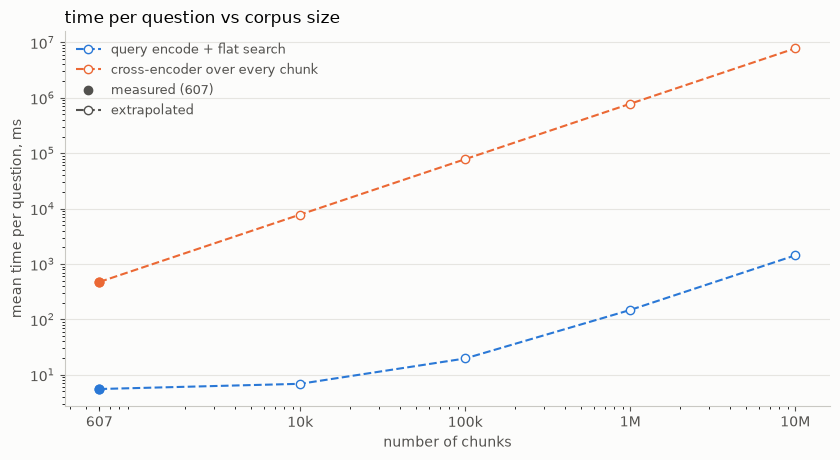

In [32]:
#filled dot = measured at 607, hollow dots on the dashed line = extrapolated
figure, axis = plt.subplots(figsize=(8.5, 4.7), facecolor=SURFACE)
style_axis(axis)
for column, name, color in (("baseline_ms", "query encode + flat search", SERIES),
                             ("cross_encoder_ms", "cross-encoder over every chunk", ORANGE)):
    axis.plot(scaling.chunks, scaling[column], linestyle="--", marker="o", markerfacecolor=SURFACE, color=color, label=name)
    axis.scatter([len(chunks)], [scaling.iloc[0][column]], color=color, s=40, zorder=4)
axis.set(xscale="log", yscale="log", xlabel="number of chunks", ylabel="mean time per question, ms")
axis.set_title("time per question vs corpus size", loc="left")
axis.set_xticks(SCALING_SIZES, ["607", "10k", "100k", "1M", "10M"])
handles, _ = axis.get_legend_handles_labels()
handles += [Line2D([0], [0], color=MUTED, marker="o", linestyle="", label="measured (607)"),
            Line2D([0], [0], color=MUTED, marker="o", markerfacecolor=SURFACE, linestyle="--", label="extrapolated")]
axis.legend(handles=handles, frameon=False, labelcolor=MUTED, fontsize=9)
figure.tight_layout()
figure.savefig(FIGURES / "scaling.png", dpi=200, facecolor=SURFACE)
plt.show()
plt.close(figure)
RUN_INFO["scaling"] = {"measured_chunks": len(chunks), "queries": len(eval_queries), "batch_size": SCALING_BATCH_SIZE,
                       "warmup_pairs": SCALING_BATCH_SIZE, "mean_full_corpus_ce_ms": mean_ce,
                       "pairs_per_second": throughput, "mean_query_encode_ms": mean_encode, "mean_flat_search_ms": mean_search,
                       "bi_encoder_side": "from the isolated latency trials", "extrapolated_sizes": list(SCALING_SIZES[1:]),
                       "extrapolation": "fixed pair throughput; encode + linear scan from 607; excludes sorting and I/O"}
save_run_info()

## numbers summary

every headline number from this run in one table. retrieval quality = eval set only, answer numbers = the proposed labels

In [33]:
number_rows = []
for pipeline in ("baseline", "rerank"):
    #retrieval quality, eval set
    for metric in ("hit@3", "facts@3", "sufficient@3", "rr@10"):
        number_rows.append({"area": "retrieval quality", "measure": "mrr@10" if metric == "rr@10" else metric,
                            "pipeline": pipeline, "value": float(eval_metrics[f"{pipeline}_{metric}"].mean()), "unit": "fraction", "n": len(eval_queries)})
    #answers, proposed labels
    for metric in ("facts_stated", "correct", "wrong", "unsupported", "refused"):
        number_rows.append({"area": "proposed answer labels", "measure": metric, "pipeline": pipeline,
                            "value": float(eval_answer_summary.loc[pipeline, metric]), "unit": "fraction", "n": len(eval_queries)})
    #latency, isolated retrieval has 160 samples, everything live has 16
    for metric in (f"{pipeline}_retrieval", f"{pipeline}_live_retrieval", f"{pipeline}_llm_wall_ms", f"{pipeline}_end_to_end_ms"):
        number_rows.append({"area": "latency", "measure": metric, "pipeline": pipeline,
                            "value": float(latency_means[metric]), "unit": "ms", "n": len(retrieval_timings) if metric == f"{pipeline}_retrieval" else len(eval_queries)})
number_rows += [
    {"area": "candidate ceiling", "measure": "facts@10", "pipeline": "shared", "value": float(eval_metrics["facts@10"].mean()), "unit": "fraction", "n": len(eval_queries)},
    {"area": "latency", "measure": "rerank_cost_isolated", "pipeline": "rerank", "value": rerank_cost["isolated_ms"], "unit": "ms", "n": len(retrieval_timings)},
    {"area": "latency", "measure": "rerank_cost_live", "pipeline": "rerank", "value": rerank_cost["live_ms"], "unit": "ms", "n": len(eval_queries)},
    {"area": "latency", "measure": "rerank_cost_live_share_of_end_to_end", "pipeline": "rerank", "value": rerank_cost["live_pct_of_rerank_end_to_end"], "unit": "%", "n": len(eval_queries)},
    {"area": "scaling at 607", "measure": "full_corpus_scoring", "pipeline": "cross_encoder", "value": mean_ce, "unit": "ms", "n": len(eval_queries)},
    {"area": "scaling at 607", "measure": "pair_throughput", "pipeline": "cross_encoder", "value": throughput, "unit": "pairs/s", "n": len(eval_queries)},
]
numbers_summary = pd.DataFrame(number_rows)
numbers_summary.to_csv(RESULTS / "numbers_summary.csv", index=False, lineterminator="\n")
display(numbers_summary.round(4))
#provenance: hashes of every input + the cache this run used
RUN_INFO["answer_cache"] = {"file": "results/answers.csv", "sha256": hashlib.sha256(ANSWERS_FILE.read_bytes()).hexdigest(),
                            "source_commit": "9d60343", "answers": len(answers), "regenerated": False}
RUN_INFO["input_hashes"] = {str(path.relative_to(ROOT)).replace("\\", "/"): hashlib.sha256(path.read_bytes()).hexdigest()
                            for path in (GDPR_PDF, EVAL_FILE, STRESS_FILE, DATA / "answer_labels.yaml")}
RUN_INFO["llm"]["placement"] = ollama_placement(LLM)
RUN_INFO["execution"] = {"finished_at": datetime.now().astimezone().isoformat(timespec="seconds"),
                         "torch_threads": torch.get_num_threads(), "faiss_threads": faiss.omp_get_max_threads(),
                         "encoder_dtype": str(next(bi_encoder.parameters()).dtype),
                         "torch_peak_allocated_mib": torch.cuda.max_memory_allocated() / (1024 ** 2) if DEVICE == "cuda" else 0,
                         "git_head": command_output(["git", "rev-parse", "HEAD"])}  # last commit when this ran, the notebook itself may have had edits on top
RUN_INFO["outputs"] = [str(path.relative_to(ROOT)).replace("\\", "/") for path in sorted(RESULTS.glob("*.csv"))]
save_run_info()
print("saved run info and numbers summary; labelled answer cache unchanged")

,area,measure,pipeline,value,unit,n
0,retrieval quality,hit@3,baseline,0.4375,fraction,16
1,retrieval quality,facts@3,baseline,0.3958,fraction,16
2,retrieval quality,sufficient@3,baseline,0.3750,fraction,16
3,retrieval quality,mrr@10,baseline,0.3761,fraction,16
4,proposed answer labels,facts_stated,baseline,0.2708,fraction,16
5,proposed answer labels,correct,baseline,0.1875,fraction,16
6,proposed answer labels,wrong,baseline,0.0625,fraction,16
7,proposed answer labels,unsupported,baseline,0.0625,fraction,16
8,proposed answer labels,refused,baseline,0.5625,fraction,16
9,latency,baseline_retrieval,baseline,5.5331,ms,160


saved run info and numbers summary; labelled answer cache unchanged
